Please upload Tweets.csv


Saving Tweets.csv to Tweets (1).csv

Dataset loaded successfully!
File: Tweets (1).csv
Dataset shape: (14640, 16)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,original_text
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada),@VirginAmerica What @dhepburn said.
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica plus you've added commercials t...
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada),@VirginAmerica I didn't today... Must mean I n...
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica it's really aggressive to blast...
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada),@VirginAmerica and it's a really big bad thing...




QUESTION 1: TWITTER TOKENIZATION

Twitter-specific features:
        Feature  Tweets containing feature  Total occurrences
        Handles                      14640              16482
       Hashtags                       2355               3472
           URLs                       1173               1211
Stretched words                        230                236
         Emojis                        493                982

TOKENIZER COMPARISON

Tweet 1:
Original: @VirginAmerica What @dhepburn said.
Naive: ['virginamerica', 'what', 'dhepburn', 'said']
Twitter-aware: ['what', 'said']

Tweet 2:
Original: @VirginAmerica plus you've added commercials to the experience... tacky.
Naive: ['virginamerica', 'plus', 'you', 've', 'added', 'commercials', 'to', 'the', 'experience', 'tacky']
Twitter-aware: ['plus', "you've", 'added', 'commercials', 'to', 'the', 'experience', 'tacky']

Tweet 3:
Original: @VirginAmerica I didn't today... Must mean I need to take another trip!
Naive: ['virginam

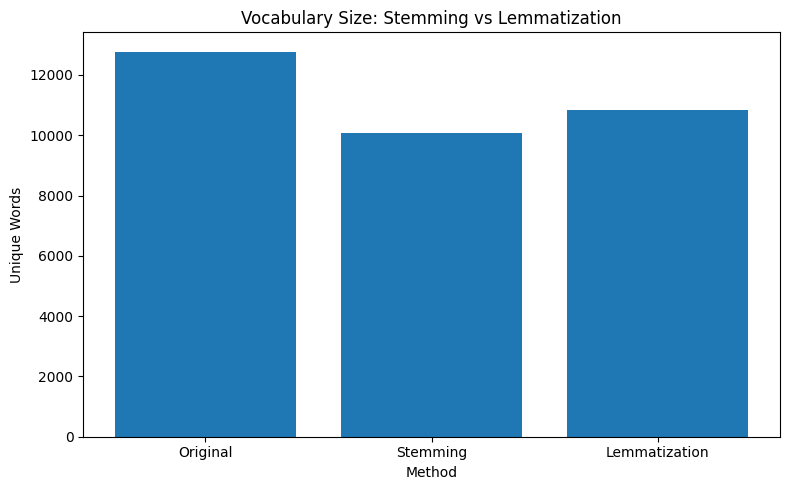

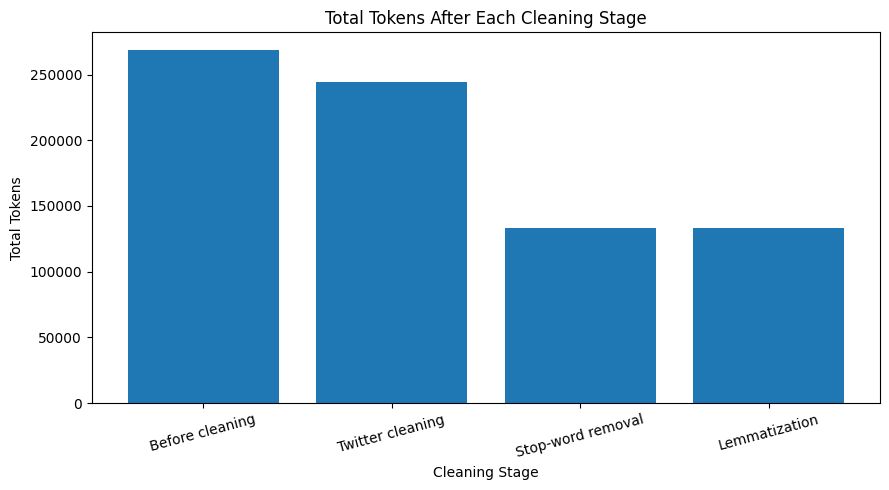

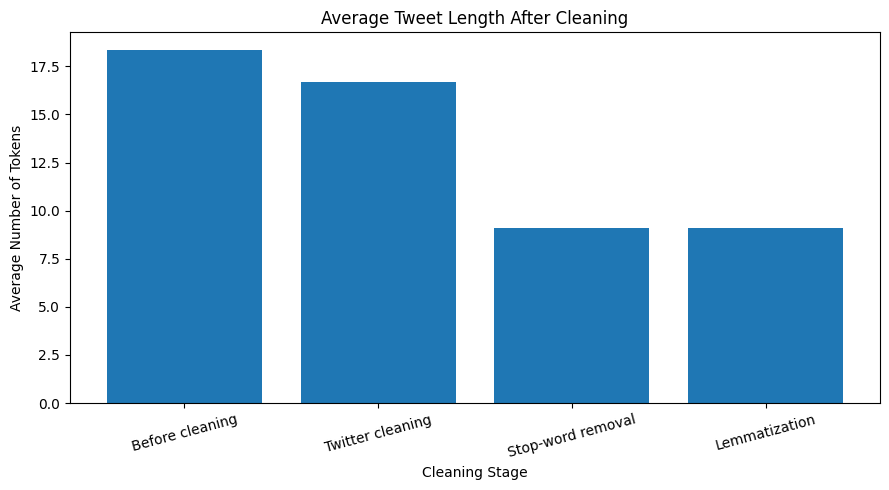

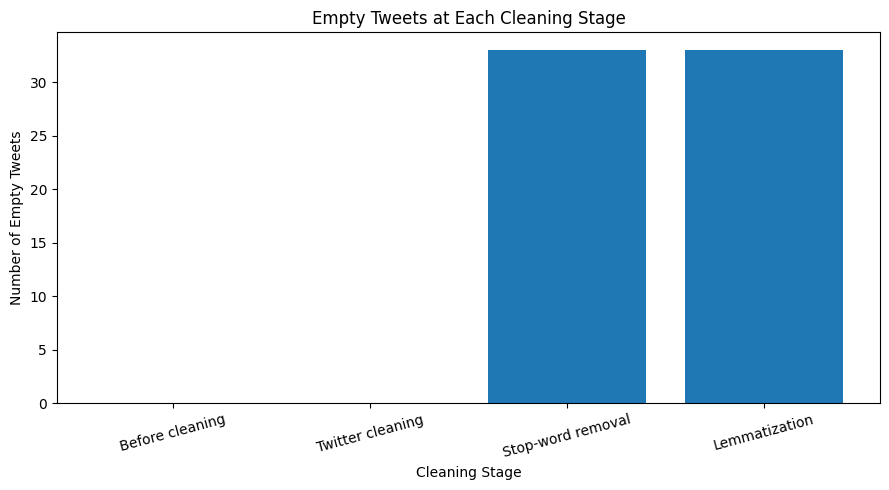



FINAL SUMMARY
Total tweets: 14640
Initial vocabulary: 15089
Vocabulary after stemming: 10090
Vocabulary after lemmatization: 10844
Empty tweets after stop-word removal: 33

FINAL RECOMMENDATIONS
1. Use Twitter-aware tokenization.
2. Remove usernames and URLs where they are not useful.
3. Preserve hashtag words and emojis.
4. Preserve negation words.
5. Use customized stop-word removal.
6. Prefer lemmatization when meaningful word forms matter.
7. Avoid excessive cleaning.

ALL FILES SAVED SUCCESSFULLY:
- cleaned_tweets.csv
- cleaning_metrics.csv
- twitter_features.csv
- vocabulary_comparison.csv
- stemming_lemmatization_comparison.csv
- negation_analysis.csv

Preparing output files for download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PART A COMPLETED SUCCESSFULLY!


In [5]:

# ============================================================
# PART A: TWITTER TEXT PREPROCESSING AND CLEANING
# Dataset: Tweets.csv
# ============================================================

%pip install -q pandas numpy nltk scikit-learn textblob regex matplotlib

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import re
import io
import regex
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from textblob import TextBlob

# Download required NLTK resources
for resource in [
    'wordnet',
    'omw-1.4',
    'averaged_perceptron_tagger_eng'
]:
    nltk.download(resource, quiet=True)


# ============================================================
# 2. UPLOAD AND LOAD DATASET
# ============================================================

print("Please upload Tweets.csv")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded.")

file_name = next(iter(uploaded))

if not file_name.lower().endswith('.csv'):
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

if 'text' not in df.columns:
    raise ValueError(
        "The dataset must contain a column named 'text'. "
        "Available columns: " + str(df.columns.tolist())
    )

df['text'] = df['text'].fillna('').astype(str)
df['original_text'] = df['text']

print("\nDataset loaded successfully!")
print("File:", file_name)
print("Dataset shape:", df.shape)
display(df.head())


# ============================================================
# 3. COMMON PATTERNS
# ============================================================

url_pattern = r'https?://\S+|www\.\S+'
mention_pattern = r'(?<!\w)@\w+'
hashtag_pattern = r'#(\w+)'
elongated_pattern = r'\b\w*(\w)\1{2,}\w*\b'

emoji_pattern = regex.compile(r'\p{Extended_Pictographic}')


# ============================================================
# QUESTION 1: TWITTER-SPECIFIC TOKENIZATION
# ============================================================

print("\n\nQUESTION 1: TWITTER TOKENIZATION")
print("================================")

feature_results = []

patterns = {
    'Handles': mention_pattern,
    'Hashtags': r'(?<!\w)#\w+',
    'URLs': url_pattern,
    'Stretched words': elongated_pattern
}

for feature, pattern in patterns.items():

    counts = df['original_text'].apply(
        lambda x: len(
            re.findall(pattern, x, flags=re.IGNORECASE)
        )
    )

    feature_results.append({
        'Feature': feature,
        'Tweets containing feature': int((counts > 0).sum()),
        'Total occurrences': int(counts.sum())
    })

emoji_counts = df['original_text'].apply(
    lambda x: len(emoji_pattern.findall(x))
)

feature_results.append({
    'Feature': 'Emojis',
    'Tweets containing feature': int(
        df['original_text'].apply(
            lambda x: bool(emoji_pattern.search(x))
        ).sum()
    ),
    'Total occurrences': int(emoji_counts.sum())
})

feature_table = pd.DataFrame(feature_results)

print("\nTwitter-specific features:")
print(feature_table.to_string(index=False))


# ------------------------------------------------------------
# Naive tokenizer
# ------------------------------------------------------------

def naive_tokenizer(text):

    return re.findall(r'\b\w+\b', str(text).lower())


# ------------------------------------------------------------
# Twitter-aware tokenizer
# ------------------------------------------------------------

def twitter_tokenizer(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(url_pattern, ' ', text)

    # Remove usernames
    text = re.sub(mention_pattern, ' ', text)

    # Preserve hashtag words
    text = re.sub(hashtag_pattern, r'\1', text)

    # Normalize stretched words
    # Example: goooood -> good
    text = re.sub(
        r'(.)\1{2,}',
        lambda m: m.group(1) * 2,
        text
    )

    # Preserve words, contractions, numbers and emojis
    tokens = regex.findall(
        r"[a-z]+(?:'[a-z]+)?|\d+(?:\.\d+)?|\p{Extended_Pictographic}",
        text
    )

    return tokens


# ------------------------------------------------------------
# Compare tokenizers
# ------------------------------------------------------------

print("\nTOKENIZER COMPARISON")

for i, tweet in enumerate(df['original_text'].head(10)):

    print(f"\nTweet {i + 1}:")
    print("Original:", tweet)
    print("Naive:", naive_tokenizer(tweet))
    print("Twitter-aware:", twitter_tokenizer(tweet))


# ============================================================
# QUESTION 2: STOP-WORD REMOVAL
# ============================================================

print("\n\nQUESTION 2: STOP-WORD REMOVAL")
print("================================")

stop_words = set(ENGLISH_STOP_WORDS)

# Preserve negation words
negation_words = {
    'not', 'no', 'nor', 'never',
    "don't", "doesn't", "didn't",
    "can't", "cannot", "couldn't",
    "won't", "wouldn't", "isn't",
    "aren't", "wasn't", "weren't",
    "haven't", "hasn't", "hadn't",
    "shouldn't", "mustn't", "needn't"
}

# Preserve sentiment intensifiers
important_words = {
    'very', 'really', 'too', 'so',
    'more', 'most', 'less', 'least'
}

stop_words = stop_words - negation_words - important_words


def remove_stopwords(tokens):

    return [
        word for word in tokens
        if word not in stop_words
    ]


# Tokenize tweets
df['tokens_before_stopwords'] = df['original_text'].apply(
    twitter_tokenizer
)

# Remove stop words
df['tokens_after_stopwords'] = (
    df['tokens_before_stopwords'].apply(remove_stopwords)
)


# ------------------------------------------------------------
# Demonstrate negation impact
# ------------------------------------------------------------

examples = [
    "The flight is good.",
    "The flight is not good.",
    "I am happy.",
    "I am not happy.",
    "No one helped me.",
    "The service was never good."
]

print("\nNEGATION EXAMPLES")

for sentence in examples:

    tokens = twitter_tokenizer(sentence)

    without_negation = [
        word for word in tokens
        if word not in negation_words
    ]

    print("\nOriginal:", sentence)
    print("With negation:", tokens)
    print("Without negation:", without_negation)


# ------------------------------------------------------------
# Measure sentiment impact of removing negations
# ------------------------------------------------------------

negation_pattern = re.compile(
    r"\b(?:not|no|nor|never)\b|n't\b",
    flags=re.IGNORECASE
)

negation_df = df[
    df['original_text'].str.contains(
        negation_pattern,
        na=False
    )
].copy()

negation_df['without_negation'] = (
    negation_df['original_text'].apply(
        lambda x: negation_pattern.sub('', x)
    )
)

negation_df['original_polarity'] = (
    negation_df['original_text'].apply(
        lambda x: TextBlob(x).sentiment.polarity
    )
)

negation_df['modified_polarity'] = (
    negation_df['without_negation'].apply(
        lambda x: TextBlob(x).sentiment.polarity
    )
)

negation_df['polarity_changed'] = (
    np.sign(negation_df['original_polarity']) !=
    np.sign(negation_df['modified_polarity'])
)

print("\nSENTIMENT IMPACT")

print("Tweets containing negation:", len(negation_df))

if len(negation_df) > 0:

    print(
        "Original average polarity:",
        round(negation_df['original_polarity'].mean(), 4)
    )

    print(
        "Polarity after removing negation:",
        round(negation_df['modified_polarity'].mean(), 4)
    )

    print(
        "Tweets with changed polarity:",
        int(negation_df['polarity_changed'].sum())
    )

    print(
        "Percentage changed:",
        round(negation_df['polarity_changed'].mean() * 100, 2),
        "%"
    )

else:
    print("No tweets containing the selected negation words.")


# ============================================================
# QUESTION 3: STEMMING VS LEMMATIZATION
# ============================================================

print("\n\nQUESTION 3: STEMMING VS LEMMATIZATION")
print("======================================")

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


# Convert POS tags into WordNet POS tags
def get_wordnet_pos(tag):

    if tag.startswith('J'):
        return wordnet.ADJ

    elif tag.startswith('V'):
        return wordnet.VERB

    elif tag.startswith('N'):
        return wordnet.NOUN

    elif tag.startswith('R'):
        return wordnet.ADV

    return wordnet.NOUN


# Stemming
def stem_tokens(tokens):

    return [
        stemmer.stem(word) if word.isalpha() else word
        for word in tokens
    ]


# Lemmatization
def lemmatize_tokens(tokens):

    if not tokens:
        return []

    tagged_words = pos_tag(tokens)

    result = []

    for word, tag in tagged_words:

        if word.isalpha():

            pos = get_wordnet_pos(tag)

            result.append(
                lemmatizer.lemmatize(word, pos)
            )

        else:
            result.append(word)

    return result


# ------------------------------------------------------------
# Create vocabulary
# ------------------------------------------------------------

all_tokens = [
    word
    for tweet in df['tokens_before_stopwords']
    for word in tweet
]

original_vocabulary = set(all_tokens)

stemmed_vocabulary = set(
    stem_tokens(list(original_vocabulary))
)

lemmatized_vocabulary = set(
    lemmatize_tokens(list(original_vocabulary))
)


# Vocabulary comparison
vocab_comparison = pd.DataFrame({
    'Method': [
        'Original',
        'Stemming',
        'Lemmatization'
    ],
    'Vocabulary Size': [
        len(original_vocabulary),
        len(stemmed_vocabulary),
        len(lemmatized_vocabulary)
    ]
})

print("\nVOCABULARY COMPARISON")
print(vocab_comparison.to_string(index=False))

original_size = len(original_vocabulary)

print("\nVOCABULARY REDUCTION")

if original_size > 0:

    print(
        "Stemming:",
        round(
            (1 - len(stemmed_vocabulary) / original_size) * 100,
            2
        ),
        "%"
    )

    print(
        "Lemmatization:",
        round(
            (1 - len(lemmatized_vocabulary) / original_size) * 100,
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# Compare words where methods differ
# ------------------------------------------------------------

comparison_words = [
    'flying', 'airlines', 'services',
    'loved', 'amazing', 'delayed',
    'running', 'better', 'worst',
    'cars', 'studies', 'was'
]

comparison_table = []

for word in comparison_words:

    stem = stemmer.stem(word)

    tagged = pos_tag([word])
    pos = get_wordnet_pos(tagged[0][1])

    lemma = lemmatizer.lemmatize(word, pos)

    comparison_table.append({
        'Original Word': word,
        'Stemmed': stem,
        'Lemmatized': lemma
    })

comparison_df = pd.DataFrame(comparison_table)

print("\nWORD COMPARISON")
print(comparison_df.to_string(index=False))


# ============================================================
# QUESTION 4: MEASURING INFORMATION LOSS
# ============================================================

print("\n\nQUESTION 4: INFORMATION LOSS")
print("=============================")


# Stage 1: Basic tokenization
stage1 = df['original_text'].apply(
    naive_tokenizer
)


# Stage 2: Twitter-specific cleaning
stage2 = df['original_text'].apply(
    twitter_tokenizer
)


# Stage 3: Stop-word removal
stage3 = stage2.apply(
    remove_stopwords
)


# Stage 4: Lemmatization
stage4 = stage3.apply(
    lemmatize_tokens
)


# ------------------------------------------------------------
# Calculate metrics
# ------------------------------------------------------------

def calculate_metrics(tokenized_data, stage_name):

    all_words = [
        word
        for tweet in tokenized_data
        for word in tweet
    ]

    total_tokens = len(all_words)
    vocabulary = len(set(all_words))

    lengths = [
        len(tweet)
        for tweet in tokenized_data
    ]

    empty_tweets = sum(
        len(tweet) == 0
        for tweet in tokenized_data
    )

    average_length = (
        np.mean(lengths)
        if lengths else 0
    )

    return {
        'Cleaning Stage': stage_name,
        'Total Tweets': len(tokenized_data),
        'Total Tokens': total_tokens,
        'Vocabulary Size': vocabulary,
        'Average Tweet Length': round(average_length, 2),
        'Empty Tweets': empty_tweets
    }


results = [
    calculate_metrics(stage1, 'Before cleaning'),
    calculate_metrics(stage2, 'Twitter cleaning'),
    calculate_metrics(stage3, 'Stop-word removal'),
    calculate_metrics(stage4, 'Lemmatization')
]

metrics_df = pd.DataFrame(results)

print("\nCLEANING STAGE COMPARISON")
print(metrics_df.to_string(index=False))


# ------------------------------------------------------------
# Information loss between stages
# ------------------------------------------------------------

print("\nINFORMATION LOSS BETWEEN STAGES")

for i in range(1, len(results)):

    previous = results[i - 1]
    current = results[i]

    token_loss = (
        (previous['Total Tokens'] - current['Total Tokens'])
        / previous['Total Tokens'] * 100
        if previous['Total Tokens'] else 0
    )

    vocab_loss = (
        (previous['Vocabulary Size'] - current['Vocabulary Size'])
        / previous['Vocabulary Size'] * 100
        if previous['Vocabulary Size'] else 0
    )

    print(
        f"\n{previous['Cleaning Stage']} -> "
        f"{current['Cleaning Stage']}"
    )

    print("Token reduction:", round(token_loss, 2), "%")
    print("Vocabulary reduction:", round(vocab_loss, 2), "%")

    print(
        "Change in empty tweets:",
        current['Empty Tweets'] - previous['Empty Tweets']
    )


# ------------------------------------------------------------
# Show tweets that became empty
# ------------------------------------------------------------

empty_tweets = [
    i for i, tweet in enumerate(stage3)
    if len(tweet) == 0
]

print("\nEMPTY TWEETS AFTER STOP-WORD REMOVAL:", len(empty_tweets))

for i in empty_tweets[:10]:
    print("\nTweet:", df.iloc[i]['original_text'])


# ============================================================
# 5. VISUALIZATIONS
# ============================================================

# Vocabulary comparison
plt.figure(figsize=(8, 5))

plt.bar(
    vocab_comparison['Method'],
    vocab_comparison['Vocabulary Size']
)

plt.title('Vocabulary Size: Stemming vs Lemmatization')
plt.xlabel('Method')
plt.ylabel('Unique Words')

plt.tight_layout()
plt.show()


# Total tokens after cleaning
plt.figure(figsize=(9, 5))

plt.bar(
    metrics_df['Cleaning Stage'],
    metrics_df['Total Tokens']
)

plt.title('Total Tokens After Each Cleaning Stage')
plt.xlabel('Cleaning Stage')
plt.ylabel('Total Tokens')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# Average tweet length
plt.figure(figsize=(9, 5))

plt.bar(
    metrics_df['Cleaning Stage'],
    metrics_df['Average Tweet Length']
)

plt.title('Average Tweet Length After Cleaning')
plt.xlabel('Cleaning Stage')
plt.ylabel('Average Number of Tokens')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# Empty tweets
plt.figure(figsize=(9, 5))

plt.bar(
    metrics_df['Cleaning Stage'],
    metrics_df['Empty Tweets']
)

plt.title('Empty Tweets at Each Cleaning Stage')
plt.xlabel('Cleaning Stage')
plt.ylabel('Number of Empty Tweets')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 6. FINAL SUMMARY
# ============================================================

print("\n\nFINAL SUMMARY")
print("==============")

print("Total tweets:", len(df))

print(
    "Initial vocabulary:",
    metrics_df.iloc[0]['Vocabulary Size']
)

print(
    "Vocabulary after stemming:",
    len(stemmed_vocabulary)
)

print(
    "Vocabulary after lemmatization:",
    len(lemmatized_vocabulary)
)

print(
    "Empty tweets after stop-word removal:",
    metrics_df.iloc[2]['Empty Tweets']
)

print("\nFINAL RECOMMENDATIONS")

print("1. Use Twitter-aware tokenization.")
print("2. Remove usernames and URLs where they are not useful.")
print("3. Preserve hashtag words and emojis.")
print("4. Preserve negation words.")
print("5. Use customized stop-word removal.")
print("6. Prefer lemmatization when meaningful word forms matter.")
print("7. Avoid excessive cleaning.")


# ============================================================
# 7. SAVE OUTPUT FILES
# ============================================================

df['cleaned_text'] = stage4.apply(
    lambda tokens: ' '.join(tokens)
)

# Save all results
output_files = {
    'cleaned_tweets.csv': df,
    'cleaning_metrics.csv': metrics_df,
    'twitter_features.csv': feature_table,
    'vocabulary_comparison.csv': vocab_comparison,
    'stemming_lemmatization_comparison.csv': comparison_df,
    'negation_analysis.csv': negation_df
}

for filename, data in output_files.items():
    data.to_csv(filename, index=False)

print("\nALL FILES SAVED SUCCESSFULLY:")

for filename in output_files:
    print("-", filename)


# ============================================================
# 8. DOWNLOAD OUTPUT FILES
# ============================================================

print("\nPreparing output files for download...")

for filename in output_files:
    files.download(filename)

print("\nPART A COMPLETED SUCCESSFULLY!")


Dataset shape: (14640, 19)

Sentiment distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


QUESTION 5: AIRLINE NAME DOMINANCE

TOP 25 WORDS IN RAW DATA
  Word  Frequency
    to       8653
   the       6063
     i       5460
     a       4589
   you       4141
   for       4001
flight       3951
    on       3814
   and       3733
    my       3289
    is       2831
    in       2588
    of       2124
    me       1925
    it       1911
  your       1743
  have       1646
   was       1607
   not       1586
  with       1523
    no       1509
  that       1506
    at       1491
  this       1393
   get       1342

Airline names found in dataset:
['airways', 'america', 'american', 'delta', 'southwest', 'united', 'us', 'virgin']

TOP 25 WORDS AFTER REMOVING AIRLINE NAMES AND FILLER
     Word  Frequency
   flight       3951
   thanks       1083
cancelled       1065
  service        967
     help        873
     time        794
 cust

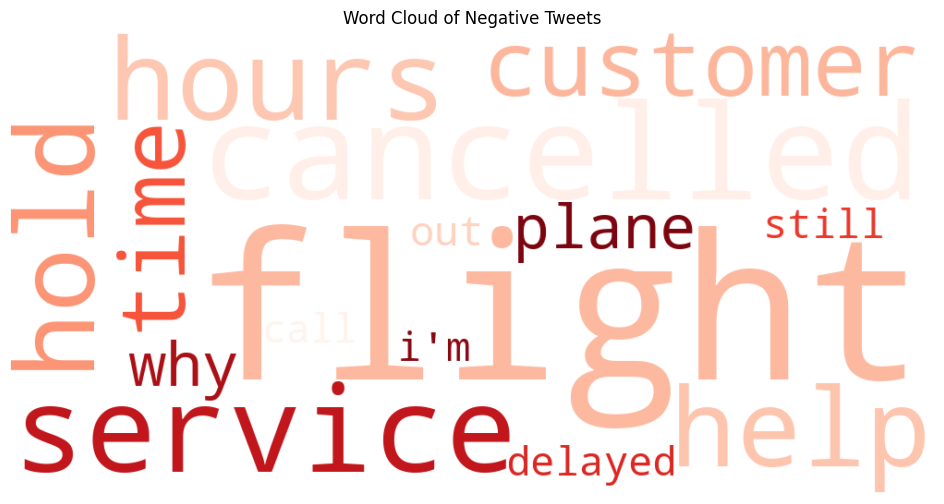

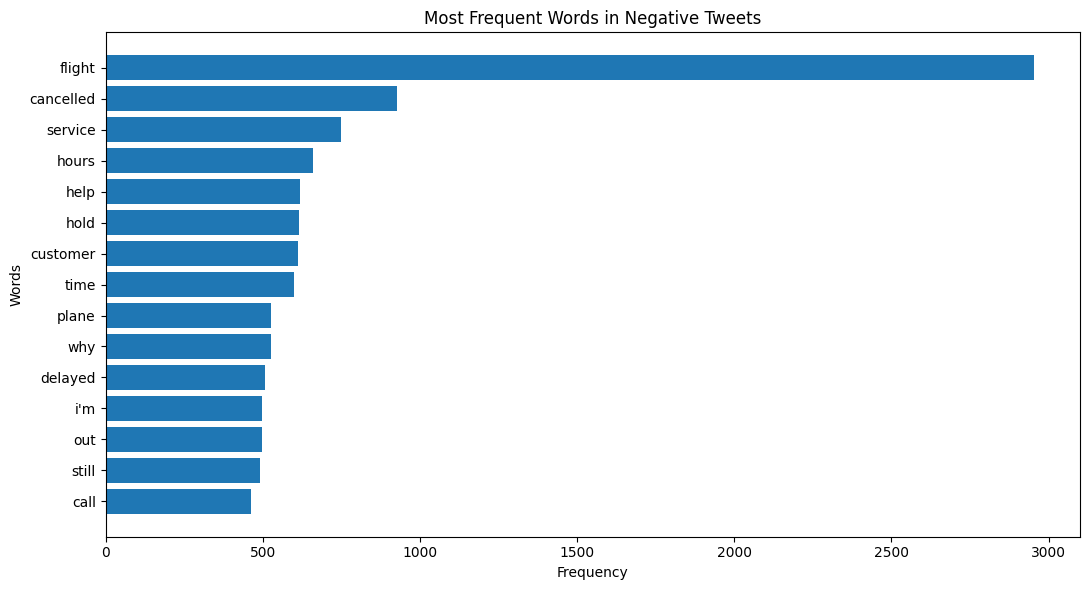


QUESTION 8 EXPLANATION
I would present the bar chart to the Director. It displays exact frequencies and makes it easier to compare the most common complaint-related words.
A word cloud is visually attractive and quickly highlights prominent terms, but it does not communicate exact values or make close comparisons as clearly as a bar chart.

PART B OUTPUT FILES
- partB_raw_top_words.csv
- partB_cleaned_top_words.csv
- partB_distinctive_words.csv
- partB_negative_bigrams.csv
- partB_negative_trigrams.csv
- partB_top_negative_words.csv

PART B COMPLETED SUCCESSFULLY!


In [7]:

# ============================================================
# PART B: FREQUENCY, DISTINCTIVE WORDS, PHRASES AND VISUALIZATION
# Dataset: Tweets.csv
# Requires df from Part A
# ============================================================

%pip install -q wordcloud scikit-learn

import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
from textblob import TextBlob


# ============================================================
# 1. CHECK DATASET
# ============================================================

if 'df' not in globals():
    raise ValueError("Run Part A first so that df is loaded.")

required_columns = ['text', 'airline_sentiment']

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

data = df.copy()

data['text'] = data['text'].fillna('').astype(str)
data['airline_sentiment'] = (
    data['airline_sentiment'].fillna('').astype(str).str.lower()
)

# Keep positive, negative and neutral tweets
data = data[
    data['airline_sentiment'].isin(
        ['positive', 'negative', 'neutral']
    )
].copy()

print("Dataset shape:", data.shape)
print("\nSentiment distribution:")
print(data['airline_sentiment'].value_counts())


# ============================================================
# 2. TEXT CLEANING FOR WORD AND PHRASE ANALYSIS
# ============================================================

def tokenize(text):

    text = str(text).lower()

    # Remove URLs and usernames
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'(?<!\w)@\w+', ' ', text)

    # Keep words and contractions
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    return tokens


data['tokens'] = data['text'].apply(tokenize)


# ============================================================
# QUESTION 5:
# AIRLINE NAMES AND GENERIC FILLER
# ============================================================

print("\n\nQUESTION 5: AIRLINE NAME DOMINANCE")
print("===================================")

# Count words in the raw tweets
raw_words = [
    word
    for tokens in data['tokens']
    for word in tokens
]

raw_frequency = Counter(raw_words)

raw_top_words = pd.DataFrame(
    raw_frequency.most_common(25),
    columns=['Word', 'Frequency']
)

print("\nTOP 25 WORDS IN RAW DATA")
print(raw_top_words.to_string(index=False))


# Identify airline names from the airline column
airline_names = set()

if 'airline' in data.columns:

    for airline in data['airline'].dropna().unique():

        airline_tokens = tokenize(airline)

        airline_names.update(airline_tokens)

print("\nAirline names found in dataset:")
print(sorted(airline_names))


# Generic stop words and filler
generic_words = {
    'the', 'a', 'an', 'and', 'or', 'but',
    'is', 'are', 'was', 'were', 'be', 'been',
    'to', 'of', 'in', 'on', 'at', 'for', 'from',
    'with', 'by', 'as', 'it', 'this', 'that',
    'i', 'me', 'my', 'we', 'our', 'you', 'your',
    'he', 'she', 'they', 'them', 'their',
    'have', 'has', 'had', 'do', 'does', 'did',
    'will', 'would', 'can', 'could', 'should',
    'not', 'no', 'so', 'if', 'about', 'what',
    'when', 'where', 'who', 'how', 'there',
    'here', 'just', 'than', 'then', 'now',
    'all', 'very', 'really', 'also', 'amp',
    'get', 'got', 'one', 'go', 'going',
    'im', 'ive', 'youre', 'dont', 'didnt',
    'thats', 'its', 'weve', 'cant'
}

# Airline names and generic words are removed for this comparison
excluded_words = generic_words | airline_names

useful_words = [
    word for word in raw_words
    if word not in excluded_words and len(word) > 2
]

cleaned_frequency = Counter(useful_words)

cleaned_top_words = pd.DataFrame(
    cleaned_frequency.most_common(25),
    columns=['Word', 'Frequency']
)

print("\nTOP 25 WORDS AFTER REMOVING AIRLINE NAMES AND FILLER")
print(cleaned_top_words.to_string(index=False))


# Compare before and after
print("\nQUESTION 5 EXPLANATION")

print(
    "Raw vocabulary is dominated by common words and airline names. "
    "Removing these words makes customer complaints and experiences "
    "more visible."
)

print(
    "The dominance of airline names suggests that tweets were collected "
    "using airline-related search terms, airline mentions, or airline "
    "accounts. It also reflects that customers frequently identify the "
    "airline they are discussing."
)


# Save Question 5 results
raw_top_words.to_csv('partB_raw_top_words.csv', index=False)
cleaned_top_words.to_csv('partB_cleaned_top_words.csv', index=False)


# ============================================================
# QUESTION 6:
# WORDS THAT DISTINGUISH POSITIVE AND NEGATIVE TWEETS
# ============================================================

print("\n\nQUESTION 6: DISTINCTIVE WORDS")
print("================================")

positive_data = data[
    data['airline_sentiment'] == 'positive'
]

negative_data = data[
    data['airline_sentiment'] == 'negative'
]

# Count words separately in positive and negative tweets
positive_words = [
    word
    for tokens in positive_data['tokens']
    for word in tokens
    if word not in excluded_words and len(word) > 2
]

negative_words = [
    word
    for tokens in negative_data['tokens']
    for word in tokens
    if word not in excluded_words and len(word) > 2
]

positive_counts = Counter(positive_words)
negative_counts = Counter(negative_words)

total_positive = sum(positive_counts.values())
total_negative = sum(negative_counts.values())

vocabulary = set(positive_counts) | set(negative_counts)

# Calculate smoothed log frequency ratio
# Positive values indicate association with positive tweets.
# Negative values indicate association with negative tweets.

distinctive_results = []

smoothing = 0.5

for word in vocabulary:

    pos_count = positive_counts[word]
    neg_count = negative_counts[word]

    # Require a minimum number of appearances
    if pos_count + neg_count < 10:
        continue

    positive_rate = (
        (pos_count + smoothing) /
        (total_positive + smoothing * len(vocabulary))
    )

    negative_rate = (
        (neg_count + smoothing) /
        (total_negative + smoothing * len(vocabulary))
    )

    log_ratio = np.log(
        positive_rate / negative_rate
    )

    distinctive_results.append({
        'Word': word,
        'Positive Count': pos_count,
        'Negative Count': neg_count,
        'Total Count': pos_count + neg_count,
        'Log Frequency Ratio': log_ratio
    })


distinctive_df = pd.DataFrame(distinctive_results)

distinctive_df = distinctive_df.sort_values(
    'Log Frequency Ratio',
    ascending=False
)

positive_distinctive = distinctive_df.head(20)

negative_distinctive = (
    distinctive_df.sort_values(
        'Log Frequency Ratio',
        ascending=True
    ).head(20)
)

print("\nTOP WORDS ASSOCIATED WITH POSITIVE TWEETS")
print(
    positive_distinctive[
        ['Word', 'Positive Count', 'Negative Count',
         'Log Frequency Ratio']
    ].to_string(index=False)
)

print("\nTOP WORDS ASSOCIATED WITH NEGATIVE TWEETS")
print(
    negative_distinctive[
        ['Word', 'Positive Count', 'Negative Count',
         'Log Frequency Ratio']
    ].to_string(index=False)
)


# Compare raw frequency with distinctive words
print("\nQUESTION 6 EXPLANATION")

print(
    "Raw frequency only tells us how often a word appears. "
    "It does not tell us whether that word is more strongly associated "
    "with positive or negative tweets."
)

print(
    "The log frequency ratio compares the relative frequency of a word "
    "in both sentiment groups. A positive value indicates a stronger "
    "association with positive tweets, while a negative value indicates "
    "a stronger association with negative tweets."
)

distinctive_df.to_csv(
    'partB_distinctive_words.csv',
    index=False
)


# ============================================================
# QUESTION 7:
# PHRASES THAT REVEAL OPERATIONAL PROBLEMS
# ============================================================

print("\n\nQUESTION 7: PHRASE ANALYSIS")
print("============================")

# Get negative tweets
negative_texts = negative_data['text'].tolist()

# Count two-word phrases
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words=list(set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'}),
    min_df=3,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)

bigram_matrix = bigram_vectorizer.fit_transform(
    negative_texts
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigram_names = bigram_vectorizer.get_feature_names_out()

bigram_df = pd.DataFrame({
    'Phrase': bigram_names,
    'Frequency': bigram_counts
}).sort_values(
    'Frequency',
    ascending=False
)

print("\nMOST FREQUENT TWO-WORD PHRASES IN NEGATIVE TWEETS")

print(bigram_df.head(30).to_string(index=False))


# Count three-word phrases
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    stop_words=list(set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'}),
    min_df=3,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)

trigram_matrix = trigram_vectorizer.fit_transform(
    negative_texts
)

trigram_counts = np.asarray(
    trigram_matrix.sum(axis=0)
).ravel()

trigram_names = trigram_vectorizer.get_feature_names_out()

trigram_df = pd.DataFrame({
    'Phrase': trigram_names,
    'Frequency': trigram_counts
}).sort_values(
    'Frequency',
    ascending=False
)

print("\nMOST FREQUENT THREE-WORD PHRASES IN NEGATIVE TWEETS")

print(trigram_df.head(30).to_string(index=False))


# ------------------------------------------------------------
# Find sentiment-flipping phrases
# ------------------------------------------------------------

print("\nSENTIMENT-FLIPPING PHRASE EXAMPLES")

candidate_phrases = [
    'not good',
    'not happy',
    'not bad',
    'no problem',
    'never again',
    'not helpful'
]

for phrase in candidate_phrases:

    words = phrase.split()

    phrase_polarity = TextBlob(phrase).sentiment.polarity

    individual_polarities = [
        TextBlob(word).sentiment.polarity
        for word in words
    ]

    print("\nPhrase:", phrase)
    print("Individual word polarities:", individual_polarities)
    print("Phrase polarity:", round(phrase_polarity, 4))


# Find negation-related bigrams actually occurring in negative tweets
negation_phrases = bigram_df[
    bigram_df['Phrase'].str.contains(
        r'\bnot\b|\bno\b|\bnever\b',
        case=False,
        regex=True
    )
]

print("\nNEGATION-RELATED PHRASES FOUND IN NEGATIVE TWEETS")
print(negation_phrases.head(20).to_string(index=False))


print("\nQUESTION 7 EXPLANATION")

print(
    "Phrases preserve relationships between words. For example, "
    "'customer service' points to a service-related problem, while "
    "'late flight' points to a delay. These meanings are more specific "
    "than counting words such as 'service' or 'late' separately."
)

print(
    "Negation can also change the meaning of a phrase. For example, "
    "'not good' expresses a negative meaning even though 'good' alone "
    "is positive. Similarly, 'not bad' can express a mildly positive "
    "meaning even though 'bad' alone is negative."
)


# Save phrase results
bigram_df.to_csv('partB_negative_bigrams.csv', index=False)
trigram_df.to_csv('partB_negative_trigrams.csv', index=False)


# ============================================================
# QUESTION 8:
# WORD CLOUD VS BAR CHART
# ============================================================

print("\n\nQUESTION 8: WORD CLOUD VS BAR CHART")
print("====================================")

# Select the top 15 negative words
top_negative_words = negative_counts.most_common(15)

negative_words_df = pd.DataFrame(
    top_negative_words,
    columns=['Word', 'Frequency']
)

print("\nTOP 15 NEGATIVE WORDS")
print(negative_words_df.to_string(index=False))


# ------------------------------------------------------------
# Word cloud
# ------------------------------------------------------------

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Reds'
).generate_from_frequencies(
    dict(top_negative_words)
)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Negative Tweets')
plt.show()


# ------------------------------------------------------------
# Bar chart
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

words = negative_words_df['Word'].tolist()
frequencies = negative_words_df['Frequency'].tolist()

plt.barh(words[::-1], frequencies[::-1])

plt.title('Most Frequent Words in Negative Tweets')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.tight_layout()
plt.show()


print("\nQUESTION 8 EXPLANATION")

print(
    "I would present the bar chart to the Director. "
    "It displays exact frequencies and makes it easier to compare "
    "the most common complaint-related words."
)

print(
    "A word cloud is visually attractive and quickly highlights "
    "prominent terms, but it does not communicate exact values "
    "or make close comparisons as clearly as a bar chart."
)


# ============================================================
# 9. SAVE ALL PART B RESULTS
# ============================================================

output_files = [
    'partB_raw_top_words.csv',
    'partB_cleaned_top_words.csv',
    'partB_distinctive_words.csv',
    'partB_negative_bigrams.csv',
    'partB_negative_trigrams.csv'
]

negative_words_df.to_csv(
    'partB_top_negative_words.csv',
    index=False
)

output_files.append('partB_top_negative_words.csv')

print("\nPART B OUTPUT FILES")

for filename in output_files:
    print("-", filename)

print("\nPART B COMPLETED SUCCESSFULLY!")


Dataset loaded successfully!
Total tweets: 14640

Human sentiment distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


QUESTION 9: VADER VS HUMAN LABELS

SAMPLE PREDICTIONS


,text,airline_sentiment,vader_compound,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral,0.0000,neutral
1,@VirginAmerica plus you've added commercials t...,positive,0.0000,neutral
2,@VirginAmerica I didn't today... Must mean I n...,neutral,0.0000,neutral
3,@VirginAmerica it's really aggressive to blast...,negative,-0.2716,negative
4,@VirginAmerica and it's a really big bad thing...,negative,-0.5829,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative,-0.5945,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive,0.6908,positive
7,@VirginAmerica Really missed a prime opportuni...,neutral,0.0790,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,0.7525,positive
9,"@VirginAmerica it was amazing, and arrived an ...",positive,0.7717,positive



OVERALL AGREEMENT
Accuracy: 48.99 %
Correct predictions: 7172
Incorrect predictions: 7468

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    positive       0.28      0.91      0.43      2363
    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640


PERFORMANCE BY SENTIMENT CLASS
Sentiment  Precision   Recall  F1 Score  Number of Tweets
 positive   0.282337 0.909860  0.430948              2363
 negative   0.903450 0.439420  0.591262              9178
  neutral   0.386177 0.319135  0.349470              3099

HARDEST CLASS FOR VADER
Class: neutral
F1 Score: 0.3495
Recall: 0.3191


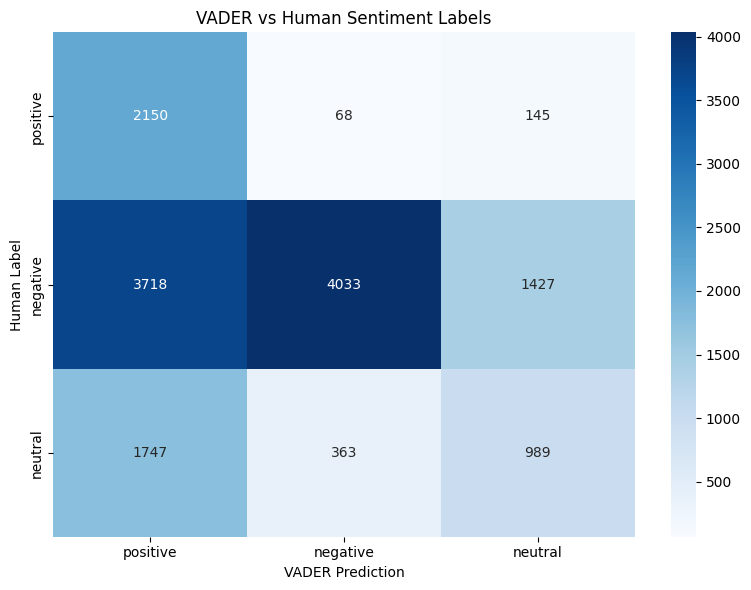


QUESTION 9 INTERPRETATION
Overall accuracy gives only the percentage of tweets classified correctly. It does not show whether positive, negative and neutral tweets are classified equally well.
The classification report and confusion matrix reveal which sentiment classes are confused with one another.
A tool can have reasonable overall accuracy while performing poorly on a less frequent sentiment class.


QUESTION 10: ANALYSING DISAGREEMENTS

TOTAL DISAGREEMENTS: 7468
Percentage of tweets with disagreement: 51.01 %

DISAGREEMENT CAUSES
                    Cause  Number of Tweets  Percentage
          Other / unclear              3954       52.95
                 Negation              2372       31.76
Airline operational words               985       13.19
                  Sarcasm               134        1.79
           Mixed feelings                23        0.31

LARGEST CAUSE OF DISAGREEMENT
Cause: Other / unclear
Tweets: 3954
Percentage: 52.95 %

MOST SEVERE DISAGREEMENTS


,text,airline_sentiment,vader_sentiment,vader_compound,disagreement_cause
11702,@USAirways YOU ARE THE BEST AIRWAYS!!!!!!!!!! ...,positive,negative,-0.9517,Other / unclear
5510,@SouthwestAir I wish i would've seen this 4 ho...,positive,negative,-0.9118,Other / unclear
4614,@SouthwestAir What can we do to bring you back...,positive,negative,-0.8617,Other / unclear
7613,@JetBlue 😭😭😭😭 yall are really better then Amer...,positive,negative,-0.8484,Other / unclear
9561,@USAirways couldn't be more thankful to your #...,positive,negative,-0.7511,Negation
13013,"@AmericanAir Well, you guys are totally kickin...",positive,negative,-0.6973,Other / unclear
8267,@JetBlue keep going back and forth with being ...,positive,negative,-0.6940,Negation
11749,@USAirways after missing my flight and reFligh...,positive,negative,-0.6688,Airline operational words
1617,@united thanks for updating me about the 1+ ho...,positive,negative,-0.6596,Airline operational words
8168,@JetBlue you don't remember our date Monday ni...,positive,negative,-0.6486,Negation


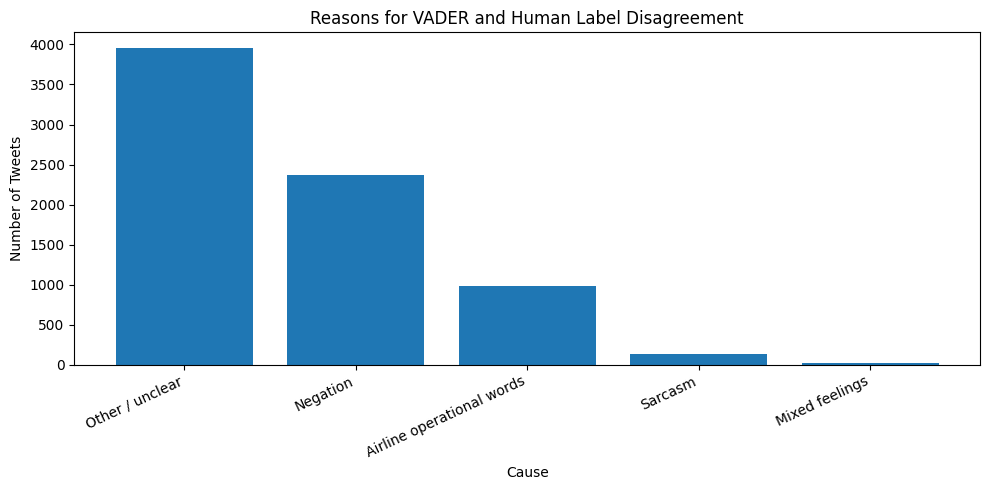


QUESTION 10 INTERPRETATION
Sarcasm can express the opposite of the literal words. Negation can reverse the meaning of a positive or negative word. Mixed feelings contain both positive and negative expressions.
Airline-specific words such as delayed, cancelled and stranded may describe negative experiences even when a general sentiment lexicon does not assign them enough negative weight.
A useful improvement is to extend the sentiment lexicon with airline-specific terms, improve negation handling, and review sarcastic or mixed tweets separately.


QUESTION 11: CUSTOM MISLEADING TWEETS

CUSTOM TWEET RESULTS


,Tweet,Expected Meaning,Reason,VADER Compound,VADER Prediction
0,Great! Another flight cancelled. Just what I n...,Negative,"Sarcasm: the word great is positive, but the c...",0.5255,positive
1,"The flight was not bad, and the crew was helpful.",Positive,Negation: not bad has a more positive meaning ...,0.6858,positive
2,"The food was amazing, but my luggage was lost ...",Negative,Mixed feelings: positive words describe the fo...,-0.4404,negative



CUSTOM TWEET ANALYSIS

Tweet: Great! Another flight cancelled. Just what I needed.
Expected meaning: Negative
VADER prediction: positive
Compound score: 0.5255
Reason: Sarcasm: the word great is positive, but the cancelled flight makes the overall message negative.
Result: VADER MISCLASSIFIED this example.

Tweet: The flight was not bad, and the crew was helpful.
Expected meaning: Positive
VADER prediction: positive
Compound score: 0.6858
Reason: Negation: not bad has a more positive meaning than the individual word bad suggests.
Result: VADER classified this example correctly.

Tweet: The food was amazing, but my luggage was lost and the flight was delayed.
Expected meaning: Negative
VADER prediction: negative
Compound score: -0.4404
Reason: Mixed feelings: positive words describe the food, but the lost luggage and delay make the overall experience negative.
Result: VADER classified this example correctly.

QUESTION 11 INTERPRETATION
These examples demonstrate that individual word sc

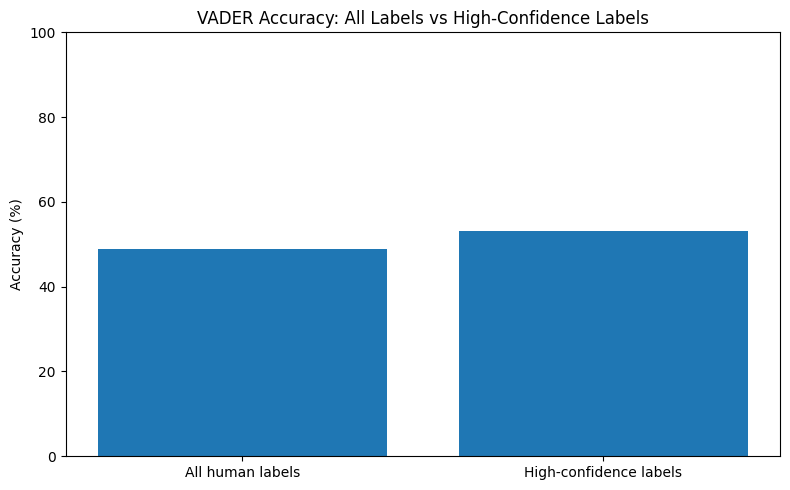


HIGH-CONFIDENCE SENTIMENT DISTRIBUTION
airline_sentiment
negative    7392
neutral     1550
positive    1517
Name: count, dtype: int64

QUESTION 12 INTERPRETATION
Agreement improved when low-confidence labels were removed. This suggests that uncertain human annotations may contribute to disagreement.
Human labels are not always perfect. Confidence scores help identify uncertain annotations, but high confidence does not guarantee that a label is correct.


SAVING PART C RESULTS

FILES SAVED:
1. partC_all_sentiment_predictions.csv
2. partC_disagreements.csv
3. partC_disagreement_causes.csv
4. partC_class_performance.csv
5. partC_custom_tweets.csv
6. partC_high_confidence_results.csv
7. partC_confidence_comparison.csv

PART C COMPLETED SUCCESSFULLY!


In [8]:

# ============================================================
# PART C: SENTIMENT ANALYSIS AND HUMAN LABEL COMPARISON
# Dataset: Tweets.csv
# ============================================================

%pip install -q vaderSentiment scikit-learn pandas numpy matplotlib seaborn

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()


# ============================================================
# 2. CHECK DATASET
# ============================================================

if 'df' not in globals():
    raise ValueError("Please run Part A first to load the dataset.")

required_columns = ['text', 'airline_sentiment']

for column in required_columns:
    if column not in df.columns:
        raise ValueError(
            f"Required column '{column}' is missing from the dataset."
        )

data = df.copy()

data['text'] = data['text'].fillna('').astype(str)

data['airline_sentiment'] = (
    data['airline_sentiment']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
)

# Keep valid human labels
valid_labels = ['positive', 'negative', 'neutral']

data = data[
    data['airline_sentiment'].isin(valid_labels)
].copy()

data = data.reset_index(drop=True)

print("Dataset loaded successfully!")
print("Total tweets:", len(data))

print("\nHuman sentiment distribution:")
print(data['airline_sentiment'].value_counts())


# ============================================================
# QUESTION 9:
# SCORE EVERY TWEET AND COMPARE WITH HUMAN LABELS
# ============================================================

print("\n\nQUESTION 9: VADER VS HUMAN LABELS")
print("=================================")


# ------------------------------------------------------------
# Score each tweet using VADER
# ------------------------------------------------------------

def get_vader_scores(text):

    return analyzer.polarity_scores(str(text))


vader_results = data['text'].apply(get_vader_scores)

# Store all four VADER scores
data['vader_negative'] = vader_results.apply(
    lambda x: x['neg']
)

data['vader_neutral'] = vader_results.apply(
    lambda x: x['neu']
)

data['vader_positive'] = vader_results.apply(
    lambda x: x['pos']
)

data['vader_compound'] = vader_results.apply(
    lambda x: x['compound']
)


# ------------------------------------------------------------
# Convert compound score into sentiment labels
# ------------------------------------------------------------

def classify_vader(compound):

    if compound >= 0.05:
        return 'positive'

    elif compound <= -0.05:
        return 'negative'

    else:
        return 'neutral'


data['vader_sentiment'] = data['vader_compound'].apply(
    classify_vader
)


# ------------------------------------------------------------
# Display examples
# ------------------------------------------------------------

print("\nSAMPLE PREDICTIONS")

display(
    data[
        [
            'text',
            'airline_sentiment',
            'vader_compound',
            'vader_sentiment'
        ]
    ].head(15)
)


# ------------------------------------------------------------
# Overall agreement
# ------------------------------------------------------------

human_labels = data['airline_sentiment']
predicted_labels = data['vader_sentiment']

accuracy = accuracy_score(
    human_labels,
    predicted_labels
)

print("\nOVERALL AGREEMENT")
print("Accuracy:", round(accuracy * 100, 2), "%")

print(
    "Correct predictions:",
    int((human_labels == predicted_labels).sum())
)

print(
    "Incorrect predictions:",
    int((human_labels != predicted_labels).sum())
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        human_labels,
        predicted_labels,
        labels=valid_labels,
        zero_division=0
    )
)


# ------------------------------------------------------------
# Find the hardest class
# ------------------------------------------------------------

precision, recall, f1, support = precision_recall_fscore_support(
    human_labels,
    predicted_labels,
    labels=valid_labels,
    zero_division=0
)

class_results = pd.DataFrame({
    'Sentiment': valid_labels,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'Number of Tweets': support
})

print("\nPERFORMANCE BY SENTIMENT CLASS")
print(class_results.to_string(index=False))

hardest_class = class_results.loc[
    class_results['F1 Score'].idxmin()
]

print("\nHARDEST CLASS FOR VADER")
print("Class:", hardest_class['Sentiment'])
print("F1 Score:", round(hardest_class['F1 Score'], 4))
print("Recall:", round(hardest_class['Recall'], 4))


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    human_labels,
    predicted_labels,
    labels=valid_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=valid_labels,
    yticklabels=valid_labels
)

plt.title('VADER vs Human Sentiment Labels')
plt.xlabel('VADER Prediction')
plt.ylabel('Human Label')

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Explain what overall accuracy hides
# ------------------------------------------------------------

print("\nQUESTION 9 INTERPRETATION")

print(
    "Overall accuracy gives only the percentage of tweets classified "
    "correctly. It does not show whether positive, negative and neutral "
    "tweets are classified equally well."
)

print(
    "The classification report and confusion matrix reveal which "
    "sentiment classes are confused with one another."
)

print(
    "A tool can have reasonable overall accuracy while performing "
    "poorly on a less frequent sentiment class."
)


# ============================================================
# QUESTION 10:
# FIND AND GROUP DISAGREEMENTS
# ============================================================

print("\n\nQUESTION 10: ANALYSING DISAGREEMENTS")
print("=====================================")


# ------------------------------------------------------------
# Identify disagreements
# ------------------------------------------------------------

data['disagreement'] = (
    data['airline_sentiment'] != data['vader_sentiment']
)

disagreements = data[
    data['disagreement']
].copy()


# Rank disagreements by severity
# Opposite positive/negative predictions receive the highest score.

def disagreement_severity(row):

    human = row['airline_sentiment']
    predicted = row['vader_sentiment']

    if (
        human == 'positive' and predicted == 'negative'
    ) or (
        human == 'negative' and predicted == 'positive'
    ):
        return 2

    return 1


disagreements['disagreement_severity'] = (
    disagreements.apply(disagreement_severity, axis=1)
)

disagreements = disagreements.sort_values(
    by=['disagreement_severity', 'vader_compound'],
    ascending=[False, True]
)

print("\nTOTAL DISAGREEMENTS:", len(disagreements))

print(
    "Percentage of tweets with disagreement:",
    round(
        len(disagreements) / len(data) * 100,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# Categorize the causes of disagreement
# ------------------------------------------------------------

sarcasm_patterns = [
    r'\byeah right\b',
    r'\bsure\b',
    r'\bgreat job\b',
    r'\bthanks a lot\b',
    r'\bwhat a joke\b',
    r'\blove waiting\b',
    r'\bjust perfect\b',
    r'\bawesome\b.*\bnot\b'
]

negation_pattern = re.compile(
    r"\b(?:not|no|nor|never|nothing|nobody|nowhere)\b|n't\b",
    flags=re.IGNORECASE
)

positive_words = {
    'good', 'great', 'excellent', 'amazing',
    'love', 'happy', 'wonderful', 'best',
    'helpful', 'friendly', 'thanks', 'thank',
    'awesome', 'perfect', 'nice'
}

negative_words = {
    'bad', 'terrible', 'worst', 'hate',
    'awful', 'horrible', 'poor', 'angry',
    'disappointed', 'unhappy', 'rude',
    'annoying', 'useless', 'disgusting'
}

airline_problem_words = {
    'delayed', 'delay', 'cancelled', 'canceled',
    'cancellation', 'cancel', 'late', 'lost',
    'missing', 'baggage', 'luggage',
    'refund', 'rebook', 'rebooking',
    'stranded', 'diverted', 'boarding',
    'connection', 'connecting', 'rescheduled'
}


def categorize_disagreement(text):

    text_lower = str(text).lower()

    # Check sarcasm patterns
    for pattern in sarcasm_patterns:

        if re.search(pattern, text_lower):
            return 'Sarcasm'

    # Check negation
    if negation_pattern.search(text_lower):
        return 'Negation'

    # Check mixed positive and negative words
    words = set(re.findall(r"[a-z']+", text_lower))

    has_positive = bool(words & positive_words)
    has_negative = bool(words & negative_words)

    if has_positive and has_negative:
        return 'Mixed feelings'

    # Check airline operational vocabulary
    if words & airline_problem_words:
        return 'Airline operational words'

    return 'Other / unclear'


disagreements['disagreement_cause'] = (
    disagreements['text'].apply(categorize_disagreement)
)


# ------------------------------------------------------------
# Count causes
# ------------------------------------------------------------

cause_counts = (
    disagreements['disagreement_cause']
    .value_counts()
    .reset_index()
)

cause_counts.columns = ['Cause', 'Number of Tweets']

cause_counts['Percentage'] = (
    cause_counts['Number of Tweets'] /
    max(len(disagreements), 1) * 100
).round(2)

print("\nDISAGREEMENT CAUSES")
print(cause_counts.to_string(index=False))


# ------------------------------------------------------------
# Find largest cause
# ------------------------------------------------------------

if len(disagreements) > 0:

    largest_cause = cause_counts.iloc[0]

    print("\nLARGEST CAUSE OF DISAGREEMENT")
    print("Cause:", largest_cause['Cause'])
    print("Tweets:", largest_cause['Number of Tweets'])
    print("Percentage:", largest_cause['Percentage'], "%")

else:

    print("\nNo disagreements were found.")


# ------------------------------------------------------------
# Display most severe disagreements
# ------------------------------------------------------------

print("\nMOST SEVERE DISAGREEMENTS")

display(
    disagreements[
        [
            'text',
            'airline_sentiment',
            'vader_sentiment',
            'vader_compound',
            'disagreement_cause'
        ]
    ].head(30)
)


# ------------------------------------------------------------
# Visualize disagreement causes
# ------------------------------------------------------------

if len(cause_counts) > 0:

    plt.figure(figsize=(10, 5))

    plt.bar(
        cause_counts['Cause'],
        cause_counts['Number of Tweets']
    )

    plt.title('Reasons for VADER and Human Label Disagreement')
    plt.xlabel('Cause')
    plt.ylabel('Number of Tweets')

    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.show()


print("\nQUESTION 10 INTERPRETATION")

print(
    "Sarcasm can express the opposite of the literal words. "
    "Negation can reverse the meaning of a positive or negative word. "
    "Mixed feelings contain both positive and negative expressions."
)

print(
    "Airline-specific words such as delayed, cancelled and stranded "
    "may describe negative experiences even when a general sentiment "
    "lexicon does not assign them enough negative weight."
)

print(
    "A useful improvement is to extend the sentiment lexicon with "
    "airline-specific terms, improve negation handling, and review "
    "sarcastic or mixed tweets separately."
)


# ============================================================
# QUESTION 11:
# THREE CUSTOM TWEETS THAT MISLEAD SENTIMENT TOOLS
# ============================================================

print("\n\nQUESTION 11: CUSTOM MISLEADING TWEETS")
print("======================================")

custom_tweets = [
    {
        'Tweet': "Great! Another flight cancelled. Just what I needed.",
        'Expected Meaning': 'Negative',
        'Reason': (
            "Sarcasm: the word great is positive, but the cancelled "
            "flight makes the overall message negative."
        )
    },
    {
        'Tweet': "The flight was not bad, and the crew was helpful.",
        'Expected Meaning': 'Positive',
        'Reason': (
            "Negation: not bad has a more positive meaning than the "
            "individual word bad suggests."
        )
    },
    {
        'Tweet': "The food was amazing, but my luggage was lost and the flight was delayed.",
        'Expected Meaning': 'Negative',
        'Reason': (
            "Mixed feelings: positive words describe the food, but "
            "the lost luggage and delay make the overall experience negative."
        )
    }
]

custom_df = pd.DataFrame(custom_tweets)

# Score custom tweets
custom_scores = custom_df['Tweet'].apply(
    lambda x: analyzer.polarity_scores(x)
)

custom_df['VADER Compound'] = custom_scores.apply(
    lambda x: x['compound']
)

custom_df['VADER Prediction'] = (
    custom_df['VADER Compound'].apply(classify_vader)
)

print("\nCUSTOM TWEET RESULTS")

display(custom_df)


# ------------------------------------------------------------
# Explain individual failures
# ------------------------------------------------------------

print("\nCUSTOM TWEET ANALYSIS")

for index, row in custom_df.iterrows():

    print("\nTweet:", row['Tweet'])
    print("Expected meaning:", row['Expected Meaning'])
    print("VADER prediction:", row['VADER Prediction'])
    print("Compound score:", round(row['VADER Compound'], 4))
    print("Reason:", row['Reason'])

    if row['VADER Prediction'] != row['Expected Meaning'].lower():

        print("Result: VADER MISCLASSIFIED this example.")

    else:

        print("Result: VADER classified this example correctly.")


print("\nQUESTION 11 INTERPRETATION")

print(
    "These examples demonstrate that individual word scores do not "
    "always represent the meaning of a complete sentence."
)

print(
    "Sarcasm, negation and mixed feelings require context and "
    "relationships between words. A lexicon-based tool may not "
    "understand these relationships correctly."
)


# ============================================================
# QUESTION 12:
# HUMAN LABEL CONFIDENCE ANALYSIS
# ============================================================

print("\n\nQUESTION 12: LABEL CONFIDENCE")
print("================================")

# Find possible confidence columns
possible_confidence_columns = [
    'airline_sentiment_confidence',
    'sentiment_confidence',
    'label_confidence',
    'confidence'
]

confidence_column = None

for column in possible_confidence_columns:

    if column in data.columns:
        confidence_column = column
        break


if confidence_column is not None:

    print("Confidence column found:", confidence_column)

    # Convert confidence values to numeric
    data[confidence_column] = pd.to_numeric(
        data[confidence_column],
        errors='coerce'
    )

    # Display confidence statistics
    print("\nCONFIDENCE STATISTICS")

    print(
        data[confidence_column].describe()
    )

    # Select high-confidence labels
    # Threshold = 0.80
    high_confidence_data = data[
        data[confidence_column] >= 0.80
    ].copy()

    print("\nHIGH-CONFIDENCE LABELS")
    print("Threshold: 0.80")
    print("Total high-confidence tweets:", len(high_confidence_data))

    if len(high_confidence_data) > 0:

        high_accuracy = accuracy_score(
            high_confidence_data['airline_sentiment'],
            high_confidence_data['vader_sentiment']
        )

        print(
            "Accuracy on high-confidence tweets:",
            round(high_accuracy * 100, 2),
            "%"
        )

        print("\nHIGH-CONFIDENCE CLASSIFICATION REPORT")

        print(
            classification_report(
                high_confidence_data['airline_sentiment'],
                high_confidence_data['vader_sentiment'],
                labels=valid_labels,
                zero_division=0
            )
        )

        # Compare full dataset and high-confidence subset
        confidence_comparison = pd.DataFrame({
            'Dataset': [
                'All human labels',
                'High-confidence labels'
            ],
            'Number of Tweets': [
                len(data),
                len(high_confidence_data)
            ],
            'VADER Accuracy (%)': [
                round(accuracy * 100, 2),
                round(high_accuracy * 100, 2)
            ]
        })

        print("\nCONFIDENCE COMPARISON")

        print(
            confidence_comparison.to_string(index=False)
        )

        # Compare accuracy visually
        plt.figure(figsize=(8, 5))

        plt.bar(
            confidence_comparison['Dataset'],
            confidence_comparison['VADER Accuracy (%)']
        )

        plt.title('VADER Accuracy: All Labels vs High-Confidence Labels')
        plt.ylabel('Accuracy (%)')
        plt.ylim(0, 100)

        plt.tight_layout()
        plt.show()

        # Show sentiment distribution in high-confidence subset
        print("\nHIGH-CONFIDENCE SENTIMENT DISTRIBUTION")

        print(
            high_confidence_data['airline_sentiment']
            .value_counts()
        )

        print("\nQUESTION 12 INTERPRETATION")

        if high_accuracy > accuracy:

            print(
                "Agreement improved when low-confidence labels were "
                "removed. This suggests that uncertain human annotations "
                "may contribute to disagreement."
            )

        elif high_accuracy < accuracy:

            print(
                "Agreement decreased after keeping only high-confidence "
                "labels. This suggests that the remaining tweets may be "
                "more difficult for VADER, even though human annotators "
                "were more confident."
            )

        else:

            print(
                "Agreement remained approximately the same after "
                "filtering low-confidence labels."
            )

        print(
            "Human labels are not always perfect. Confidence scores help "
            "identify uncertain annotations, but high confidence does "
            "not guarantee that a label is correct."
        )

    else:

        print(
            "No tweets met the 0.80 confidence threshold. "
            "Try a lower threshold such as 0.70."
        )

else:

    print("No label-confidence column was found in the dataset.")

    print(
        "Therefore, a high-confidence comparison cannot be performed "
        "with the available columns."
    )

    print(
        "The analysis can still compare VADER with the available human "
        "labels, but it cannot measure how certain the annotators were."
    )


# ============================================================
# 7. SAVE PART C OUTPUTS
# ============================================================

print("\n\nSAVING PART C RESULTS")
print("======================")

data.to_csv(
    'partC_all_sentiment_predictions.csv',
    index=False
)

disagreements.to_csv(
    'partC_disagreements.csv',
    index=False
)

cause_counts.to_csv(
    'partC_disagreement_causes.csv',
    index=False
)

class_results.to_csv(
    'partC_class_performance.csv',
    index=False
)

custom_df.to_csv(
    'partC_custom_tweets.csv',
    index=False
)

if confidence_column is not None and len(high_confidence_data) > 0:

    high_confidence_data.to_csv(
        'partC_high_confidence_results.csv',
        index=False
    )

    confidence_comparison.to_csv(
        'partC_confidence_comparison.csv',
        index=False
    )

print("\nFILES SAVED:")

print("1. partC_all_sentiment_predictions.csv")
print("2. partC_disagreements.csv")
print("3. partC_disagreement_causes.csv")
print("4. partC_class_performance.csv")
print("5. partC_custom_tweets.csv")

if confidence_column is not None and len(high_confidence_data) > 0:
    print("6. partC_high_confidence_results.csv")
    print("7. partC_confidence_comparison.csv")

print("\nPART C COMPLETED SUCCESSFULLY!")


Dataset shape: (14640, 19)
Airlines: ['Virgin America' 'United' 'Southwest' 'Delta' 'US Airways' 'American']

Q13: CUSTOMER SERVICE VS OPERATIONS

Complaint counts by airline:
complaint_type  Customer Service  Operations  Other / Unknown
airline                                                      
American                     855         774              331
Delta                        259         421              275
Southwest                    429         465              292
US Airways                   934         918              411
United                       849        1119              665
Virgin America                65          68               48

Complaint percentages by airline:
complaint_type  Customer Service  Operations  Other / Unknown
airline                                                      
American                   43.62       39.49            16.89
Delta                      27.12       44.08            28.80
Southwest                  36.17       39.21 

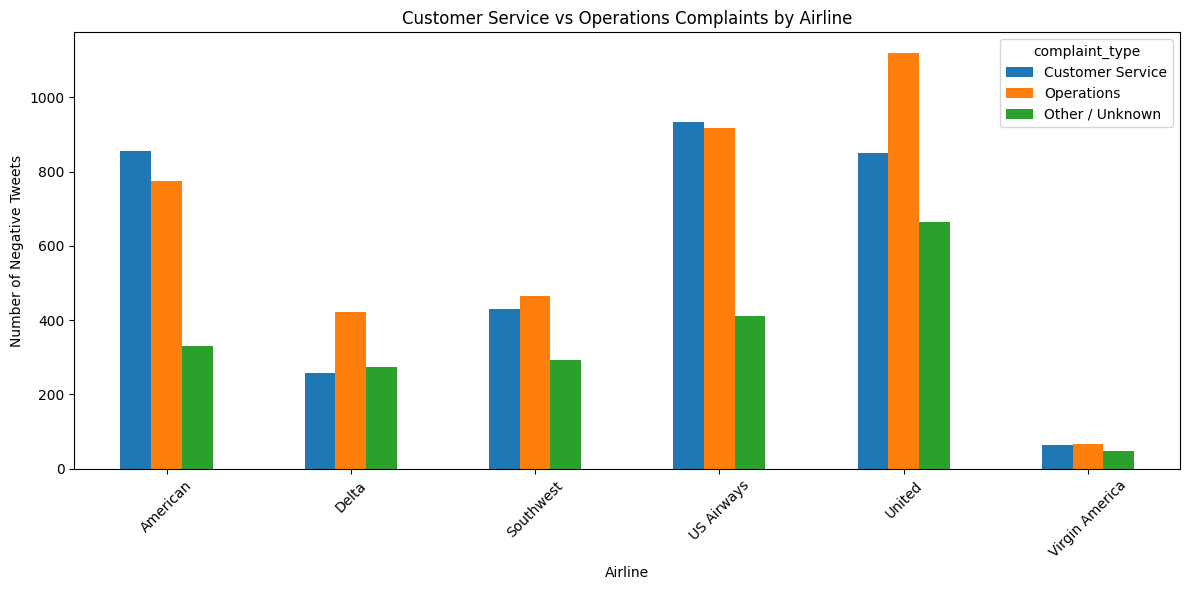

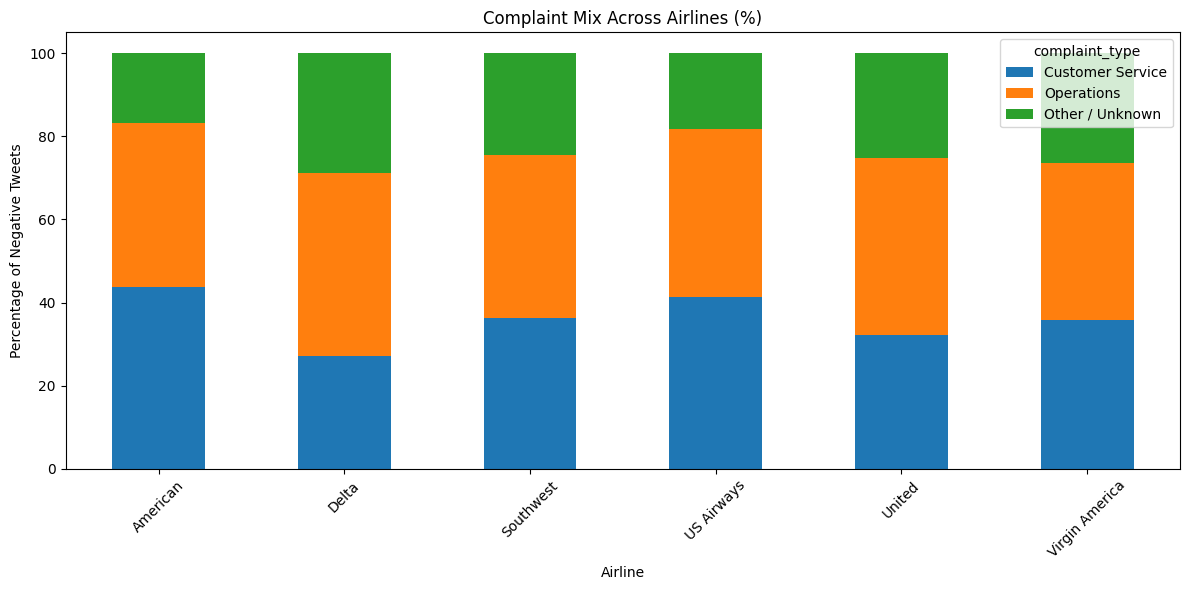


Highest customer service complaint share: American (43.62%)
Highest operations complaint share: Delta (44.08%)

Q14: RAW COUNTS VS SENTIMENT SHARES

Airline comparison:
                Total Tweets  Negative Tweets  Negative Share (%)
airline                                                          
United                  3822             2633               68.89
US Airways              2913             2263               77.69
American                2759             1960               71.04
Southwest               2420             1186               49.01
Delta                   2222              955               42.98
Virgin America           504              181               35.91

Highest raw negative count: United
Highest negative percentage: US Airways

Airlines where raw counts and percentages tell different stories:
                Total Tweets  Negative Tweets  Negative Share (%)  Count Rank  \
airline                                                                       

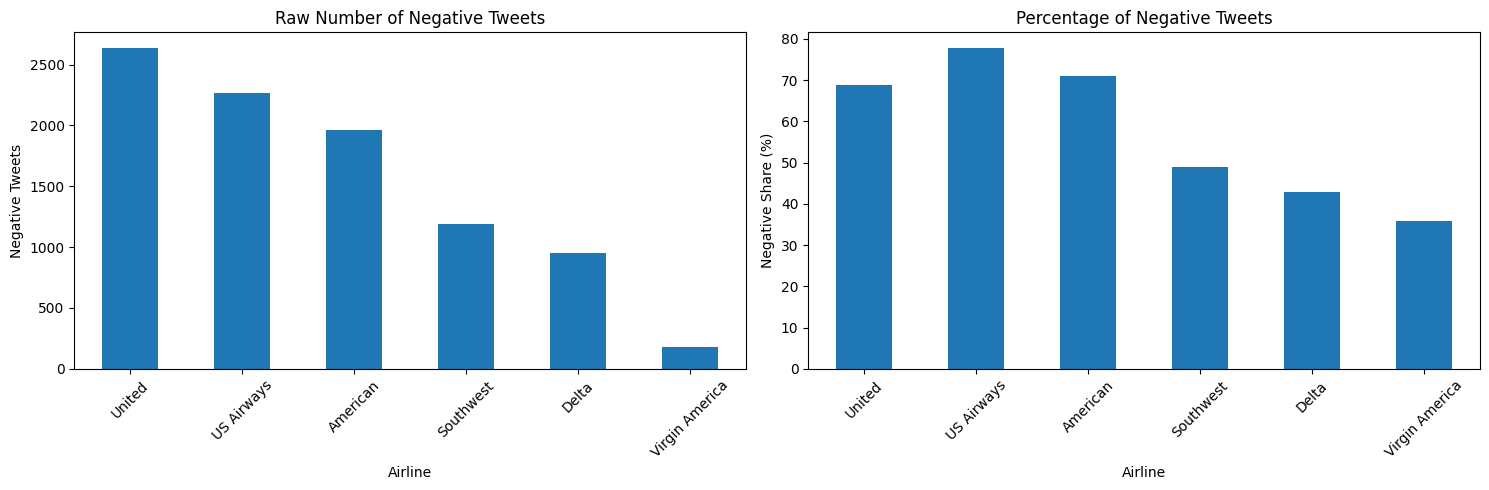


Q15: NEGATIVE SENTIMENT OVER TIME

Daily sentiment data:
            Total_Tweets  Negative_Tweets  Negative_Share (%)
day                                                          
2015-02-17           953              552           57.922350
2015-02-18          1416              827           58.403955
2015-02-19          1298              666           51.309707
2015-02-20          1512              849           56.150794
2015-02-21          1418              901           63.540197
2015-02-22          2392             1744           72.909699
2015-02-23          3515             2346           66.742532
2015-02-24          2136             1293           60.533708


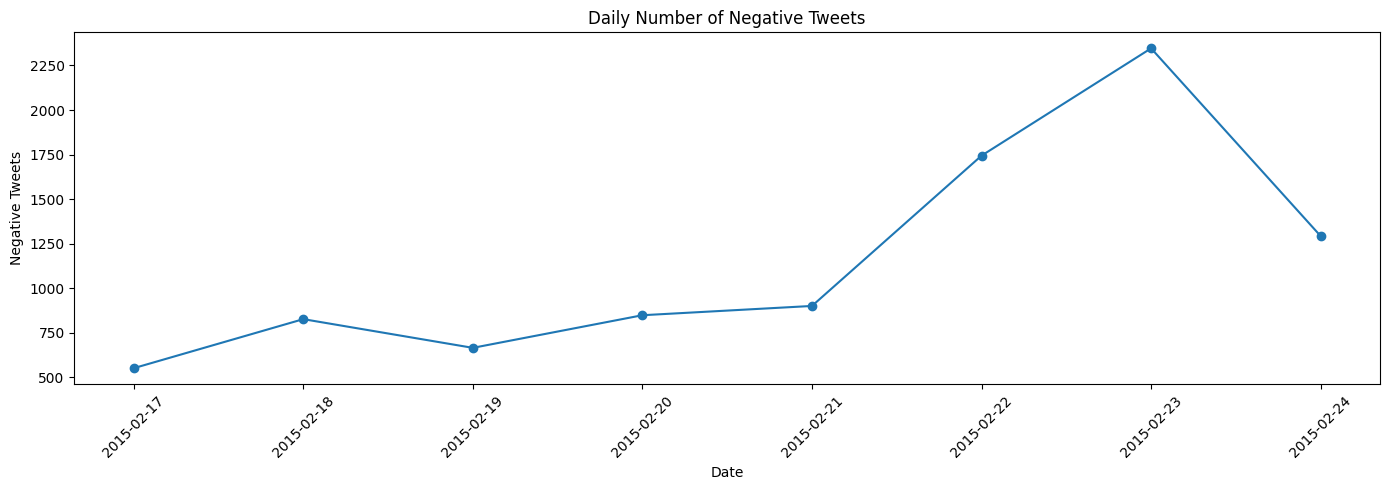

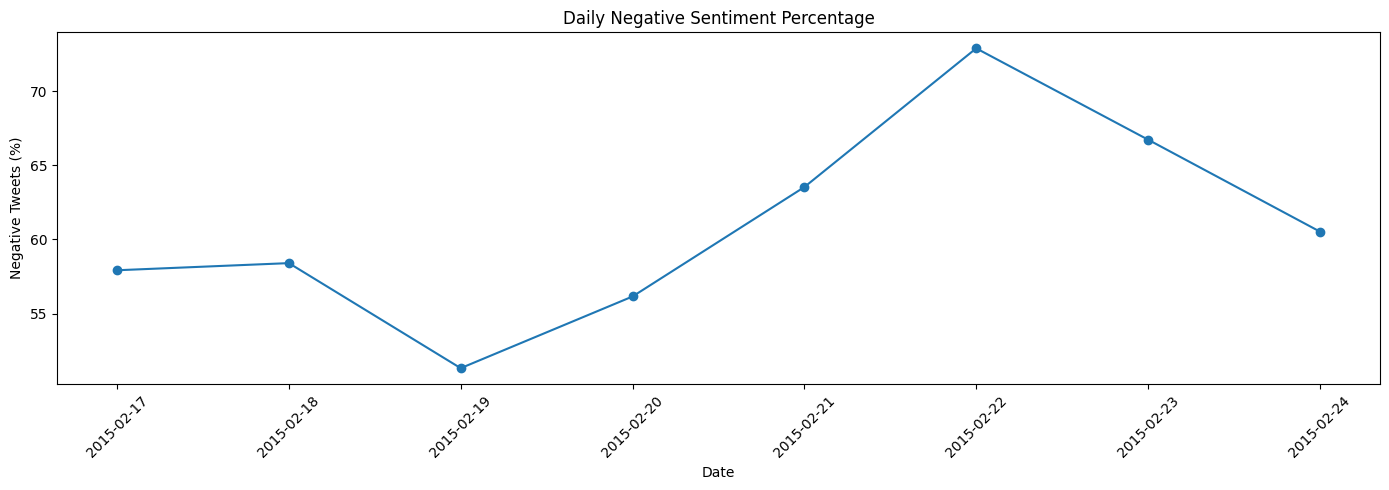

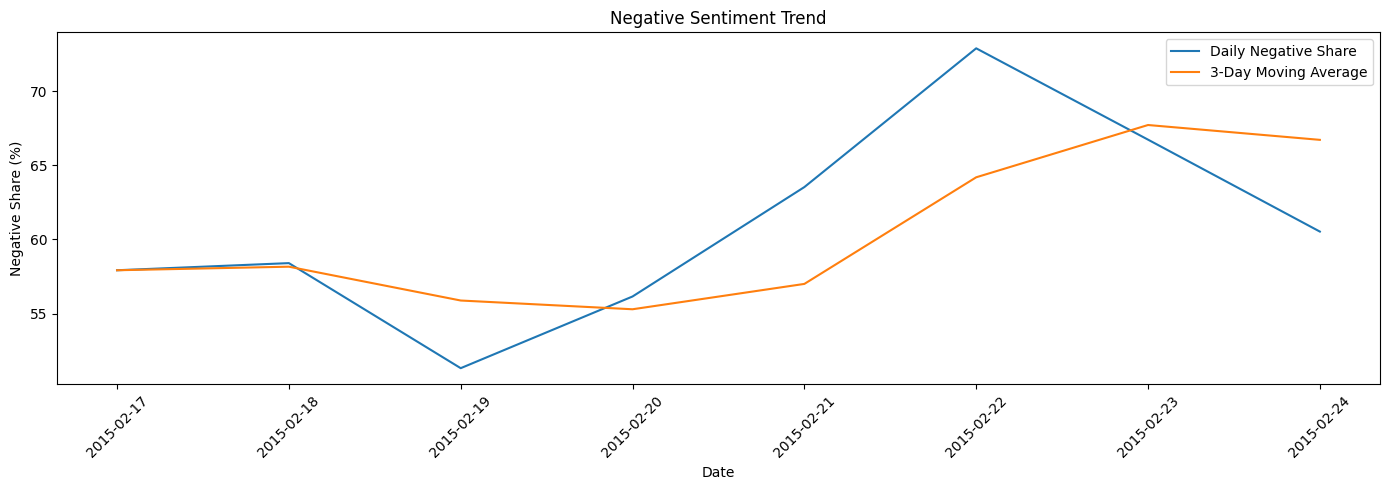


Days with the highest negative sentiment share:
            Total_Tweets  Negative_Tweets  Negative_Share (%)  \
day                                                             
2015-02-22          2392             1744               72.91   
2015-02-23          3515             2346               66.74   
2015-02-21          1418              901               63.54   
2015-02-24          2136             1293               60.53   
2015-02-18          1416              827               58.40   
2015-02-17           953              552               57.92   
2015-02-20          1512              849               56.15   
2015-02-19          1298              666               51.31   

            3-Day Moving Average  
day                               
2015-02-22                 64.20  
2015-02-23                 67.73  
2015-02-21                 57.00  
2015-02-24                 66.73  
2015-02-18                 58.16  
2015-02-17                 57.92  
2015-02-20          

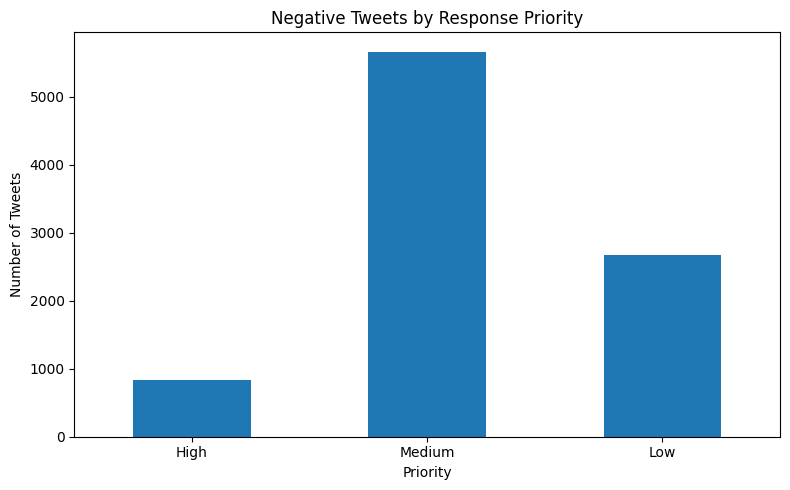


PART D COMPLETED

Generated files:
✓ partD_complaint_counts.csv
✓ partD_complaint_percentages.csv
✓ partD_airline_sentiment_comparison.csv
✓ partD_negative_tweet_priority.csv
✓ partD_daily_sentiment.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

# ============================================================
# PART D: AIRLINE COMPLAINTS, SENTIMENT, TIME AND PRIORITY
# Q13, Q14, Q15, Q16
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

# ------------------------------------------------------------
# 0. LOAD DATA
# ------------------------------------------------------------

if 'df' not in globals():
    from google.colab import files
    import io

    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

df.columns = df.columns.str.strip()

required = ['airline', 'airline_sentiment', 'text']
for col in required:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

df['airline_sentiment'] = (
    df['airline_sentiment'].astype(str).str.lower().str.strip()
)

print("Dataset shape:", df.shape)
print("Airlines:", df['airline'].unique())



# ============================================================
# Q13: CUSTOMER SERVICE VS OPERATIONS PROBLEMS
# ============================================================

print("\n" + "="*65)
print("Q13: CUSTOMER SERVICE VS OPERATIONS")
print("="*65)

negative_df = df[
    df['airline_sentiment'] == 'negative'
].copy()

if 'negativereason' not in negative_df.columns:
    raise ValueError("The dataset does not contain a negativereason column.")

negative_df['negativereason'] = (
    negative_df['negativereason']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
)

# Complaint categories
service_reasons = [
    'Customer Service Issue',
    'Flight Attendant Complaints'
]

operations_reasons = [
    'Late Flight',
    'Cancelled Flight',
    'Lost Luggage',
    'Flight Booking Problems'
]

def classify_complaint(reason):
    if reason in service_reasons:
        return 'Customer Service'
    elif reason in operations_reasons:
        return 'Operations'
    else:
        return 'Other / Unknown'

negative_df['complaint_type'] = (
    negative_df['negativereason'].apply(classify_complaint)
)

# Complaint counts
complaint_counts = pd.crosstab(
    negative_df['airline'],
    negative_df['complaint_type']
)

print("\nComplaint counts by airline:")
print(complaint_counts)

# Complaint percentages
complaint_percentages = pd.crosstab(
    negative_df['airline'],
    negative_df['complaint_type'],
    normalize='index'
) * 100

print("\nComplaint percentages by airline:")
print(complaint_percentages.round(2))

# Plot counts
complaint_counts.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Customer Service vs Operations Complaints by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Negative Tweets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot percentages
complaint_percentages.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Complaint Mix Across Airlines (%)")
plt.xlabel("Airline")
plt.ylabel("Percentage of Negative Tweets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Highest complaint shares
if 'Customer Service' in complaint_percentages.columns:
    print(
        "\nHighest customer service complaint share:",
        complaint_percentages['Customer Service'].idxmax(),
        f"({complaint_percentages['Customer Service'].max():.2f}%)"
    )

if 'Operations' in complaint_percentages.columns:
    print(
        "Highest operations complaint share:",
        complaint_percentages['Operations'].idxmax(),
        f"({complaint_percentages['Operations'].max():.2f}%)"
    )

complaint_counts.to_csv("partD_complaint_counts.csv")
complaint_percentages.to_csv("partD_complaint_percentages.csv")



# ============================================================
# Q14: RAW COUNTS VS SENTIMENT SHARES
# ============================================================

print("\n" + "="*65)
print("Q14: RAW COUNTS VS SENTIMENT SHARES")
print("="*65)

# Total tweets received by each airline
total_tweets = df.groupby('airline').size()

# Number of negative tweets per airline
negative_counts = (
    df[df['airline_sentiment'] == 'negative']
    .groupby('airline')
    .size()
)

airline_comparison = pd.DataFrame({
    'Total Tweets': total_tweets,
    'Negative Tweets': negative_counts
}).fillna(0)

airline_comparison['Negative Tweets'] = (
    airline_comparison['Negative Tweets'].astype(int)
)

airline_comparison['Negative Share (%)'] = (
    airline_comparison['Negative Tweets']
    / airline_comparison['Total Tweets'] * 100
)

airline_comparison = airline_comparison.sort_values(
    'Negative Tweets',
    ascending=False
)

print("\nAirline comparison:")
print(airline_comparison.round(2))

# Airline with highest raw negative count
highest_count_airline = airline_comparison[
    'Negative Tweets'
].idxmax()

# Airline with highest negative percentage
highest_share_airline = airline_comparison[
    'Negative Share (%)'
].idxmax()

print(
    f"\nHighest raw negative count: {highest_count_airline}"
)

print(
    f"Highest negative percentage: {highest_share_airline}"
)

# Find an airline whose raw-count and percentage rankings differ
count_ranks = airline_comparison['Negative Tweets'].rank(
    ascending=False,
    method='min'
)

share_ranks = airline_comparison['Negative Share (%)'].rank(
    ascending=False,
    method='min'
)

airline_comparison['Count Rank'] = count_ranks
airline_comparison['Share Rank'] = share_ranks

airline_comparison['Rank Difference'] = (
    airline_comparison['Count Rank']
    - airline_comparison['Share Rank']
).abs()

different_story = airline_comparison.sort_values(
    'Rank Difference',
    ascending=False
)

print("\nAirlines where raw counts and percentages tell different stories:")
print(different_story.round(2))

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

airline_comparison['Negative Tweets'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title("Raw Number of Negative Tweets")
axes[0].set_xlabel("Airline")
axes[0].set_ylabel("Negative Tweets")
axes[0].tick_params(axis='x', rotation=45)

airline_comparison['Negative Share (%)'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title("Percentage of Negative Tweets")
axes[1].set_xlabel("Airline")
axes[1].set_ylabel("Negative Share (%)")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

airline_comparison.to_csv("partD_airline_sentiment_comparison.csv")


# ============================================================
# Q15: NEGATIVE SENTIMENT OVER TIME
# ============================================================

print("\n" + "="*65)
print("Q15: NEGATIVE SENTIMENT OVER TIME")
print("="*65)

# Find the date column
date_column = None

for col in ['tweet_created', 'created_at', 'date', 'timestamp']:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    print("No date/time column was found. Q15 cannot be performed.")
else:
    df['parsed_date'] = pd.to_datetime(
        df[date_column],
        errors='coerce',
        utc=True
    )

    timed_df = df.dropna(subset=['parsed_date']).copy()

    timed_df['day'] = timed_df['parsed_date'].dt.date

    # Count all tweets and negative tweets per day
    daily_counts = timed_df.groupby('day').agg(
        Total_Tweets=('airline_sentiment', 'size'),
        Negative_Tweets=(
            'airline_sentiment',
            lambda x: (x == 'negative').sum()
        )
    )

    daily_counts['Negative_Share (%)'] = (
        daily_counts['Negative_Tweets']
        / daily_counts['Total_Tweets'] * 100
    )

    daily_counts = daily_counts.sort_index()

    print("\nDaily sentiment data:")
    print(daily_counts.head(10))

    # Plot daily negative tweet counts
    plt.figure(figsize=(14, 5))

    plt.plot(
        daily_counts.index.astype(str),
        daily_counts['Negative_Tweets'],
        marker='o'
    )

    plt.title("Daily Number of Negative Tweets")
    plt.xlabel("Date")
    plt.ylabel("Negative Tweets")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot daily negative percentage
    plt.figure(figsize=(14, 5))

    plt.plot(
        daily_counts.index.astype(str),
        daily_counts['Negative_Share (%)'],
        marker='o'
    )

    plt.title("Daily Negative Sentiment Percentage")
    plt.xlabel("Date")
    plt.ylabel("Negative Tweets (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Calculate a 3-day moving average
    daily_counts['3-Day Moving Average'] = (
        daily_counts['Negative_Share (%)']
        .rolling(window=3, min_periods=1)
        .mean()
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        daily_counts.index.astype(str),
        daily_counts['Negative_Share (%)'],
        label='Daily Negative Share'
    )

    plt.plot(
        daily_counts.index.astype(str),
        daily_counts['3-Day Moving Average'],
        label='3-Day Moving Average'
    )

    plt.title("Negative Sentiment Trend")
    plt.xlabel("Date")
    plt.ylabel("Negative Share (%)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Identify the highest negative-share days
    print("\nDays with the highest negative sentiment share:")
    print(
        daily_counts.sort_values(
            'Negative_Share (%)',
            ascending=False
        ).head(10).round(2)
    )

    # Identify the highest negative-count days
    print("\nDays with the highest number of negative tweets:")
    print(
        daily_counts.sort_values(
            'Negative_Tweets',
            ascending=False
        ).head(10)
    )

    daily_counts.to_csv("partD_daily_sentiment.csv")


# ============================================================
# Q16: PRIORITIZING NEGATIVE TWEETS
# ============================================================

print("\n" + "="*65)
print("Q16: NEGATIVE TWEET RESPONSE PRIORITY")
print("="*65)

priority_df = negative_df.copy()

# Start with a basic priority score
priority_df['Priority Score'] = 0

# 1. Complaint severity
# Operational problems can affect travel directly.
high_urgency_reasons = [
    'Cancelled Flight',
    'Lost Luggage',
    'Flight Booking Problems'
]

medium_urgency_reasons = [
    'Late Flight',
    'Customer Service Issue',
    'Flight Attendant Complaints'
]

priority_df.loc[
    priority_df['negativereason'].isin(high_urgency_reasons),
    'Priority Score'
] += 4

priority_df.loc[
    priority_df['negativereason'].isin(medium_urgency_reasons),
    'Priority Score'
] += 2

# 2. Confidence in the human sentiment label
if 'airline_sentiment_confidence' in priority_df.columns:
    confidence = pd.to_numeric(
        priority_df['airline_sentiment_confidence'],
        errors='coerce'
    ).fillna(0)

    priority_df['Priority Score'] += np.where(
        confidence >= 0.80, 2,
        np.where(confidence >= 0.60, 1, 0)
    )

# 3. Customer engagement using retweet count
if 'retweet_count' in priority_df.columns:
    retweets = pd.to_numeric(
        priority_df['retweet_count'],
        errors='coerce'
    ).fillna(0)

    priority_df['Priority Score'] += np.where(
        retweets >= 10, 2,
        np.where(retweets >= 1, 1, 0)
    )

# 4. Explicit urgent words in tweet text
urgent_words = [
    'stranded',
    'stuck',
    'missed connection',
    'missed my flight',
    'no refund',
    'lost my bag',
    'lost my luggage',
    'cancelled',
    'canceled',
    'never arrived'
]

def contains_urgent_words(text):
    text = str(text).lower()
    return any(word in text for word in urgent_words)

priority_df['Urgent Language'] = (
    priority_df['text'].apply(contains_urgent_words)
)

priority_df.loc[
    priority_df['Urgent Language'],
    'Priority Score'
] += 2

# Assign priority levels
def priority_level(score):
    if score >= 7:
        return 'High'
    elif score >= 4:
        return 'Medium'
    else:
        return 'Low'

priority_df['Response Priority'] = (
    priority_df['Priority Score'].apply(priority_level)
)

# Sort the tweets so the most urgent are first
priority_df = priority_df.sort_values(
    ['Priority Score'],
    ascending=False
)

print("\nNumber of tweets in each priority level:")
print(priority_df['Response Priority'].value_counts())

print("\nTop 20 tweets that should receive a response first:")

display_columns = [
    'airline',
    'negativereason',
    'text',
    'Priority Score',
    'Response Priority'
]

if 'airline_sentiment_confidence' in priority_df.columns:
    display_columns.append('airline_sentiment_confidence')

if 'retweet_count' in priority_df.columns:
    display_columns.append('retweet_count')

print(priority_df[display_columns].head(20).to_string(index=False))

# Plot priority distribution
priority_order = ['High', 'Medium', 'Low']

priority_counts = (
    priority_df['Response Priority']
    .value_counts()
    .reindex(priority_order, fill_value=0)
)

priority_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Negative Tweets by Response Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Save priority results
priority_df.to_csv(
    "partD_negative_tweet_priority.csv",
    index=False
)


# ============================================================
# FINAL OUTPUT FILES
# ============================================================

print("\n" + "="*65)
print("PART D COMPLETED")
print("="*65)

output_files = [
    "partD_complaint_counts.csv",
    "partD_complaint_percentages.csv",
    "partD_airline_sentiment_comparison.csv",
    "partD_negative_tweet_priority.csv"
]

if 'daily_counts' in globals():
    output_files.append("partD_daily_sentiment.csv")

print("\nGenerated files:")
for file in output_files:
    if os.path.exists(file):
        print("✓", file)

# Download all output files in Google Colab
from google.colab import files

for file in output_files:
    if os.path.exists(file):
        files.download(file)


Q17. How can this dataset mislead the airline?
1. Biased sample: Not all passengers use Twitter, so the dataset does not represent every customer.
2. Negative bias: Unhappy passengers may be more likely to post complaints than satisfied passengers.
3. Different tweet volumes: Popular airlines may receive more complaints simply because they have more customers.
4. Limited context: Short tweets, sarcasm, and unclear wording can lead to incorrect sentiment classifications.
Least trusted finding: Automated sentiment results, because the tool sometimes misunderstands sarcasm, negation, and airline-specific words.

Q18. What would change with today's tweets?
The results would likely change because airline services, customer expectations, and social media language have evolved since 2015.
- Common words and phrases would be different.
- Complaint types and their frequency may change.
- Airlines' positive and negative sentiment percentages may differ.
- Modern slang and expressions may affect automated sentiment accuracy.
General complaints about delays and cancellations would probably remain relevant.

Q19. Should automation replace the manual team?
I would argue against completely replacing the manual team.

Automated tools can analyze thousands of tweets quickly and identify general sentiment patterns. However, Part C showed that they can misunderstand sarcasm, negation, mixed feelings, and airline-specific expressions.

Human reviewers understand context better and can handle complicated complaints.


INSIGHT 1: WHICH TWEETS GET MORE ATTENTION?

Average retweets by sentiment:
                   mean  median  count
airline_sentiment                     
negative           0.09     0.0   9178
neutral            0.06     0.0   3099
positive           0.07     0.0   2363


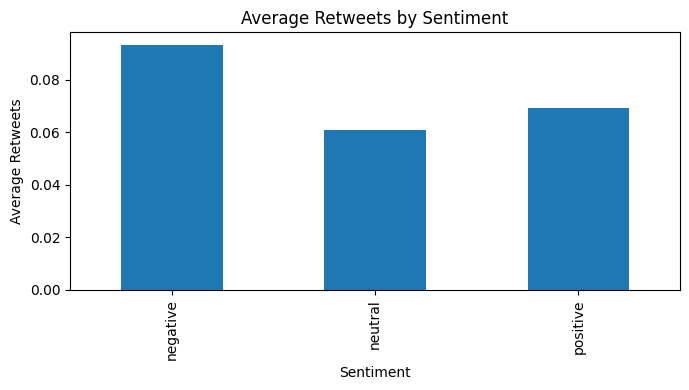


INSIGHT 2: HOW CERTAIN ARE THE SENTIMENT LABELS?

Overall sentiment confidence:
count    14640.000
mean         0.900
std          0.163
min          0.335
25%          0.692
50%          1.000
75%          1.000
max          1.000
Name: airline_sentiment_confidence, dtype: float64

Average confidence by sentiment:
airline_sentiment
negative    0.933
neutral     0.823
positive    0.872
Name: confidence, dtype: float64


<Figure size 800x400 with 0 Axes>

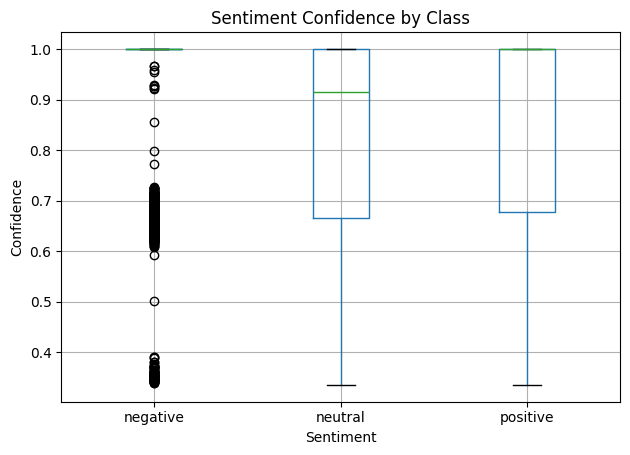


INSIGHT 3: UNCLEAR NEGATIVE COMPLAINTS
Total negative tweets: 9178
Unknown / Can't Tell complaints: 1190
Unknown complaint percentage: 12.97%

Negative complaint reasons:
negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


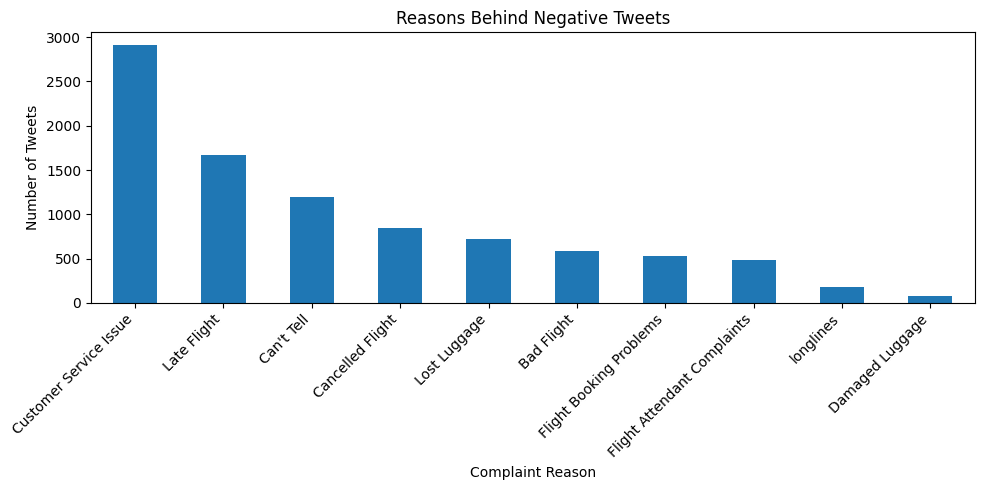


Part F analysis completed.


In [11]:

# ============================================================
# PART F: THREE ADDITIONAL INSIGHTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. RETWEET ENGAGEMENT BY SENTIMENT
print("\nINSIGHT 1: WHICH TWEETS GET MORE ATTENTION?")

engagement = df.copy()
engagement['retweet_count'] = pd.to_numeric(
    engagement['retweet_count'], errors='coerce'
).fillna(0)

print("\nAverage retweets by sentiment:")
print(
    engagement.groupby('airline_sentiment')['retweet_count']
    .agg(['mean', 'median', 'count']).round(2)
)

engagement.groupby('airline_sentiment')['retweet_count'].mean().plot(
    kind='bar', figsize=(7, 4)
)
plt.title("Average Retweets by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Retweets")
plt.tight_layout()
plt.show()


# 2. CONFIDENCE IN SENTIMENT LABELS
print("\nINSIGHT 2: HOW CERTAIN ARE THE SENTIMENT LABELS?")

confidence_col = 'airline_sentiment_confidence'

if confidence_col in df.columns:
    confidence = pd.to_numeric(
        df[confidence_col], errors='coerce'
    )

    print("\nOverall sentiment confidence:")
    print(confidence.describe().round(3))

    print("\nAverage confidence by sentiment:")
    print(
        df.assign(confidence=confidence)
        .groupby('airline_sentiment')['confidence']
        .mean().round(3)
    )

    plt.figure(figsize=(8, 4))
    df.assign(confidence=confidence).boxplot(
        column='confidence',
        by='airline_sentiment'
    )
    plt.title("Sentiment Confidence by Class")
    plt.suptitle("")
    plt.xlabel("Sentiment")
    plt.ylabel("Confidence")
    plt.tight_layout()
    plt.show()
else:
    print("Sentiment confidence column not available.")


# 3. WHICH NEGATIVE COMPLAINTS ARE UNCLEAR?
print("\nINSIGHT 3: UNCLEAR NEGATIVE COMPLAINTS")

negative = df[
    df['airline_sentiment'] == 'negative'
].copy()

negative['negativereason'] = (
    negative['negativereason'].fillna('Unknown')
)

unknown_count = negative['negativereason'].isin(
    ['Unknown', "Can't Tell"]
).sum()

total_negative = len(negative)

unknown_percentage = (
    unknown_count / total_negative * 100
    if total_negative else 0
)

print("Total negative tweets:", total_negative)
print("Unknown / Can't Tell complaints:", unknown_count)
print(f"Unknown complaint percentage: {unknown_percentage:.2f}%")

reason_counts = negative['negativereason'].value_counts()

print("\nNegative complaint reasons:")
print(reason_counts)

reason_counts.plot(
    kind='bar', figsize=(10, 5)
)
plt.title("Reasons Behind Negative Tweets")
plt.xlabel("Complaint Reason")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Save results
engagement.groupby('airline_sentiment')['retweet_count'].agg(
    ['mean', 'median', 'count']
).to_csv("partF_engagement.csv")

reason_counts.to_csv("partF_complaint_reasons.csv")

print("\nPart F analysis completed.")
